# 08 · Dates and codes

For anyone checking how Open Altio reads the dates and codes FDA publishes. Each section asks its questions, answers each with a chart, and ends with a list, one item per chart: what it shows, its point, and so what. The decisions at the end name the rule file each one lives in, and the one question still open.

1. Which dates can be true: the floor and ceiling on event and therapy dates.
2. Event dates padded to the 1st since 2021Q3.
3. Time to onset.
4. Therapy duration.
5. Reporter type.
6. Report type: what 30DAY and 5DAY mean.
7. Frequency, repeated drug numbers and dose form.
8. Outcomes: their order, and cases with none.
9. Dechallenge and rechallenge.

**The standard.** Open Altio reads FAERS against one written standard: E2B(R3) code lists, ISO, MedDRA PT and INN. Here that means the ICH E2B(R3) code lists (implementation package v1.11, January 2026: reporter qualification, recurrence on re-administration), FDA's own E2B(R3) regional values where ICH has none (report type; FDA, *Electronic Submission of Adverse Event Reports to FAERS using ICH E2B(R3) Standards*, <https://www.fda.gov/media/135633/download>) and FDA's README for what each FAERS code means. DiAna (Fusaroli et al., *Drug Safety* 2024;47:271-284, [PMC10874306](https://pmc.ncbi.nlm.nih.gov/articles/PMC10874306/)) is the rule set we compare against; its cleaning code is `Cleaning_script.R` in DiAna's OSF project [zqu89](https://osf.io/zqu89/).

**What it reads.** A release folder of every quarter, built by the command line (`open-altio build`; `open-altio demo` builds one quarter, too few for the charts by quarter): `RELEASE` in the first code cell, or `OPEN_ALTIO_RELEASE`. Reference files, never committed, read only:

| where | files | source | licence |
|---|---|---|---|
| `OPEN_ALTIO_E2B_CODE_LISTS` | the folder `7_E2B Bilingual Code Lists v2.11` (code list 6 is read, as genericode XML) | ICH E2B(R3) Implementation Package v1.11, `IG_Complete_Package_v1_11_1.zip`, <https://admin.ich.org/sites/default/files/inline-files/IG_Complete_Package_v1_11_1.zip> | ICH's: may be reproduced with ICH's copyright acknowledged |
| `OPEN_ALTIO_DIANA_LOOKUPS` | `dose_form_st.csv`, `dose_freq_st.csv` | DiAna's OSF project [zqu89](https://osf.io/zqu89/), folder "Others", files of 2026-03-23 | CC BY 4.0 (Fusaroli et al.) |
| `OPEN_ALTIO_DOSE_FORM_CHECK` | `compare.csv` | Altio's dose form check: the 176 dose form spellings that cover 99% of drug rows, each read twice, apart, against DiAna's 163 forms, and set beside DiAna's own answer. It is not yet published: it will go out with the reviewed dose form table (section 7) | Altio's |

```sh
REF=reference; mkdir -p $REF/ich $REF/diana
curl -L -o $REF/ich/package.zip https://admin.ich.org/sites/default/files/inline-files/IG_Complete_Package_v1_11_1.zip
(cd $REF/ich && unzip package.zip)   # OPEN_ALTIO_E2B_CODE_LISTS is the code list folder inside
curl -L -o $REF/diana/dose_form_st.csv https://osf.io/download/6rbkg/
curl -L -o $REF/diana/dose_freq_st.csv https://osf.io/download/53h2v/
```

Working tables are temporary, in memory; DuckDB spills beside the executed notebook (`notebooks/out/`). Nothing is written to the release.

**What it counts.** The cases a user sees by default: the latest version of each case, less FDA's deleted cases and the probable duplicates (`case_dedup_T`; the first cell prints how many). Dates and codes on a case (event date, reporter, report type) are counted in **cases**. Dates and codes on a drug or a therapy line (start date, frequency, dechallenge) are counted in **rows**, FDA's own rows, and each number says which; time to onset is counted in **drug records**, one per case and drug sequence number. FDA's values stay as FDA wrote them; anything derived ends in `_T`. Every headline number is counted twice, by two differently written queries, and the cell says "checked twice".

**What it backs.** Five rules act on the release this notebook reads, and it compares FDA's text with what they write: `event-date-precision` and `date-limits` (the event date `event_dt_T` with its precision `event_dt_prec_T`; each therapy's `start_dt_T`, `end_dt_T` and their `_prec_T`), `time-to-onset` (`drug_onset_T.time_to_onset_T`), `therapy-duration` (`ther_latest_T.dur_days_T`) and `reporter-type` (`reporter_type_T`). Two readings belong to other steps, with their own evidence: routes to the route step (`drug-route`), and fields filled with a value that says nothing, the rechallenge filler among them, to the rule for values not given (`not-given`). The rules read their values from the rule files, and so does this notebook.

In [1]:
import os
import xml.etree.ElementTree as ET
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from open_altio import rulebook
from open_altio.faers.insights.cards import compute_cards
from open_altio.faers.insights.cards.notebook import (
    ERA,
    SERIES,
    label_bars,
    out_dir,
    plot_card,
    quarter_ticks,
    setup,
    title,
    write_cards,
)
from open_altio.faers.insights.source import connect, release_folder
from open_altio.faers.reader import read_manifest

setup(colwidth=90)


def need(name):
    value = os.environ.get(name)
    assert value, f"set {name} (see the first cell)"
    return Path(value).expanduser()


# The release this notebook reads; None reads $OPEN_ALTIO_RELEASE.
# No release yet? Build one with `open-altio build` (`open-altio demo` builds one quarter only).
RELEASE = None
SOURCE = release_folder(RELEASE)
CODE_LISTS = need("OPEN_ALTIO_E2B_CODE_LISTS")  # ICH's code list folder, as published
DIANA = need("OPEN_ALTIO_DIANA_LOOKUPS")  # DiAna's dose form and frequency tables
DOSE_FORM_CHECK = need("OPEN_ALTIO_DOSE_FORM_CHECK")  # the dose form check (compare.csv)
WORK = out_dir() / "08_dates_and_codes"
(WORK / "tmp").mkdir(parents=True, exist_ok=True)
con = connect(SOURCE)
# other jobs share the machine
con.execute(
    "SET memory_limit = '6GB'; SET threads = 4; SET max_temp_directory_size = '20GB'; "
    "SET preserve_insertion_order = false; "
    f"SET temp_directory = '{WORK / 'tmp'}'"
)

# The rules' values, read from the rule files as the build reads them.
PAD_FROM = rulebook.value("event-date-precision", "faers_from_quarter")  # 2021q3 today
MONTH_DAY = rulebook.value("event-date-precision", "month_day")
YEAR_DAY = rulebook.value("event-date-precision", "year_month_day")
MAX_AGE = int(rulebook.value("date-limits", "max_age_years"))
BEFORE_BIRTH = int(rulebook.value("date-limits", "before_birth_years"))
FIRST_DAY = int(rulebook.value("time-to-onset", "first_dose_day"))
UNIT_DAYS = {**rulebook.value("therapy-duration", "unit_days")} | {
    u: 1 / n for u, n in rulebook.value("therapy-duration", "units_a_day").items()
}
YEAR = float(UNIT_DAYS["YR"])
AGE_MARGIN = float(rulebook.value("therapy-duration", "age_margin_years"))
LONGEST = float(rulebook.value("therapy-duration", "max_years_unknown_age"))
DIANA_CAP_YEARS = 50  # DiAna's own cap on a duration, Cleaning_script.R
DIANA_FLOOR = "1985"  # DiAna's earliest year for any date


def q(sql):
    return con.execute(sql).fetchdf()


def one(sql):
    return con.execute(sql).fetchone()[0]


def check(label, first, second):
    """Every headline number is counted twice, by two differently written queries."""
    assert first == second, f"{label}: {first} vs {second}"
    print(f"  checked twice: {label} = {first:,}")


def code_list(number):
    """One ICH code list, code to English label, from its genericode file as ICH publishes it."""
    path = next(CODE_LISTS.glob(f"E2B CL{number} *.xml"))
    rows = (
        {v.get("ColumnRef"): v.findtext("SimpleValue") for v in row.iter("Value")}
        for row in ET.parse(path).iter("Row")
    )
    return pd.Series({r["code"]: r["en"] for r in rows})


QUARTERS = q("SELECT quarter_T FROM quarters_T ORDER BY qnum_T").quarter_T.tolist()
FAERS_Q = [x for x in QUARTERS if x >= "2012q4"]
SOFT = QUARTERS[QUARTERS.index(PAD_FROM) - 1]  # the quarter before the rule starts: a soft edge
BASE = [x for x in FAERS_Q if x < SOFT]  # FAERS before any padding


def quarter_axis(ax, every=4):
    quarter_ticks(ax, QUARTERS, every)
    ax.set_xlim(-0.5, len(QUARTERS) - 0.5)


def shade(ax, first, last, label):
    i, j = QUARTERS.index(first), QUARTERS.index(last)
    ax.axvspan(i - 0.5, j + 0.5, color="#c3c2b7", alpha=0.35, lw=0, zorder=0)
    ax.text(
        (i + j) / 2, ax.get_ylim()[1], label, ha="center", va="top", fontsize=8, color="#3a3a38"
    )


def Q(x):
    return x.upper()


NAME = read_manifest(SOURCE)["release"]
RELEASE_END = pd.Period(NAME, freq="Q").end_time.strftime("%Y%m%d")
QEND = "strftime(last_day(make_date(CAST(left(quarter_T, 4) AS INT), CAST(right(quarter_T, 1) AS INT) * 3, 1)), '%Y%m%d')"

# The case set: latest versions, less FDA's deleted cases and probable duplicates. Then the child
# rows of those cases, with the columns the date and code rules write. Views, not tables: the
# release's Parquet is read again by each query instead of filling the spill folder.
con.execute(f"""CREATE OR REPLACE TEMP VIEW kept_T AS
SELECT era_T, primaryid, quarter_T, caseid, event_dt, event_dt_T, event_dt_prec_T, fda_dt, init_fda_dt, rept_dt, mfr_dt,
       rept_cod, occp_cod, reporter_type_T, age_years_T, init_year_T, {QEND} AS quarter_end_T
FROM case_dedup_T""")
con.execute("""CREATE OR REPLACE TEMP VIEW drug_k_T AS
SELECT era_T, primaryid, quarter_T, drug_seq, role_cod, dose_form, dose_freq, dechal, rechal FROM drug_dedup_T""")
con.execute(f"""CREATE OR REPLACE TEMP VIEW ther_k_T AS
SELECT era_T, primaryid, quarter_T, dsg_drug_seq, start_dt, end_dt, dur, dur_cod, start_dt_T, end_dt_T,
       start_dt_prec_T, end_dt_prec_T, dur_days_T, {QEND} AS quarter_end_T FROM ther_dedup_T""")
con.execute(
    "CREATE OR REPLACE TEMP VIEW outc_k_T AS SELECT era_T, primaryid, quarter_T, outc_cod FROM outc_dedup_T"
)
con.execute("""CREATE OR REPLACE TEMP VIEW onset_k_T AS
SELECT o.* FROM drug_onset_T o SEMI JOIN kept_T k USING (era_T, primaryid, quarter_T)""")
N_CASES = one("SELECT count(*) FROM kept_T")
kept_join = "FROM case_latest_T c JOIN case_dup_T d USING (era_T, case_key_T) WHERE d.dup_kept_T"  # the case set again, for the second counts
print(
    f"Release read: {SOURCE.name} ({NAME}, last day {RELEASE_END}). Code lists: {CODE_LISTS.name}. "
    f"DiAna's tables: {DIANA.name}. Dose form check: {DOSE_FORM_CHECK.name}."
)
print(
    f"Cases: {N_CASES:,}. Drug rows: {one('SELECT count(*) FROM drug_k_T'):,}. Therapy rows: {one('SELECT count(*) FROM ther_k_T'):,}. "
    f"Outcome rows: {one('SELECT count(*) FROM outc_k_T'):,}. Drug records: {one('SELECT count(*) FROM onset_k_T'):,}."
)
print(
    f"Rules: padding read from {Q(PAD_FROM)}; floor {MAX_AGE} years before receipt, or {BEFORE_BIRTH} year before birth; "
    f"duration cap the age plus {AGE_MARGIN:g} year, else {LONGEST:g} years."
)
check(
    "cases in the default case set",
    N_CASES,
    one(
        "SELECT count(*) FROM case_latest_T WHERE (era_T, case_key_T) IN (SELECT (era_T, case_key_T) FROM case_dup_T WHERE dup_kept_T)"
    ),
)

Release read: 2026Q2-oap-final3-local (2026Q2, last day 20260630). Code lists: 7_E2B Bilingual Code Lists v2.11. DiAna's tables: diana. Dose form check: dfc.


Cases: 20,296,780. Drug rows: 73,926,724. Therapy rows: 25,402,465. Outcome rows: 14,684,978. Drug records: 73,228,779.
Rules: padding read from 2021Q3; floor 122 years before receipt, or 1 year before birth; duration cap the age plus 1 year, else 50 years.


  checked twice: cases in the default case set = 20,296,780


## 1. Which dates can be true?

FAERS writes every date as text: `yyyymmdd`, or `yyyymm` or `yyyy` when the sender knew less (FDA's README). E2B(R3) sets no earliest year; it says only that a date "cannot refer to a future date" and that the year is the least precision allowed (E.i.4, G.k.4.r.4). DiAna keeps a date only between 1985 and the last day of the newest quarter.

**The limits are a range, with a floor and a ceiling.** A date outside them cannot be true, so a time worked out from it would be wrong. Nothing is deleted: FDA's text stays as published, and our clean copy of that date (`_T`) is left empty, so no time to onset or duration is worked out from it.

- **The ceiling** is the last day of the quarter the case version was published in: a date cannot be later than the file that holds it. A case published in the 2018Q3 file cannot have an event on 15 March 2019. A partial date is compared at its own precision: `201809` is not after 2018Q3, `201810` is.
- **The floor** follows the patient. The oldest person on record lived 122 years, so a date more than 122 years before FDA first received the case is impossible for anyone; that is only a backstop. Where the age is known, a therapy date may not be more than a year before the patient's birth: in a report about a child exposed in the womb, the mother's treatment starts before the birth. The birth year is the event year, else the year FDA first received the case, less the age. An event date has only the 122-year floor, since the age is the age at the event.
- **Which dates.** The event date and each therapy's start and end, the dates times are worked out from. The report, receipt and manufacturer dates are not checked (the third chart says why).
- **Each date is counted once**, under the first test it fails, in the order the charts list them.

DiAna's 1985 floor removes true therapy dates, decades of thyroid or anticonvulsant treatment among them, and misses impossible ones from after 1985: a start before a 30-year-old was born. The first chart counts what the limits catch; the second splits the therapy starts before birth by DiAna's floor.

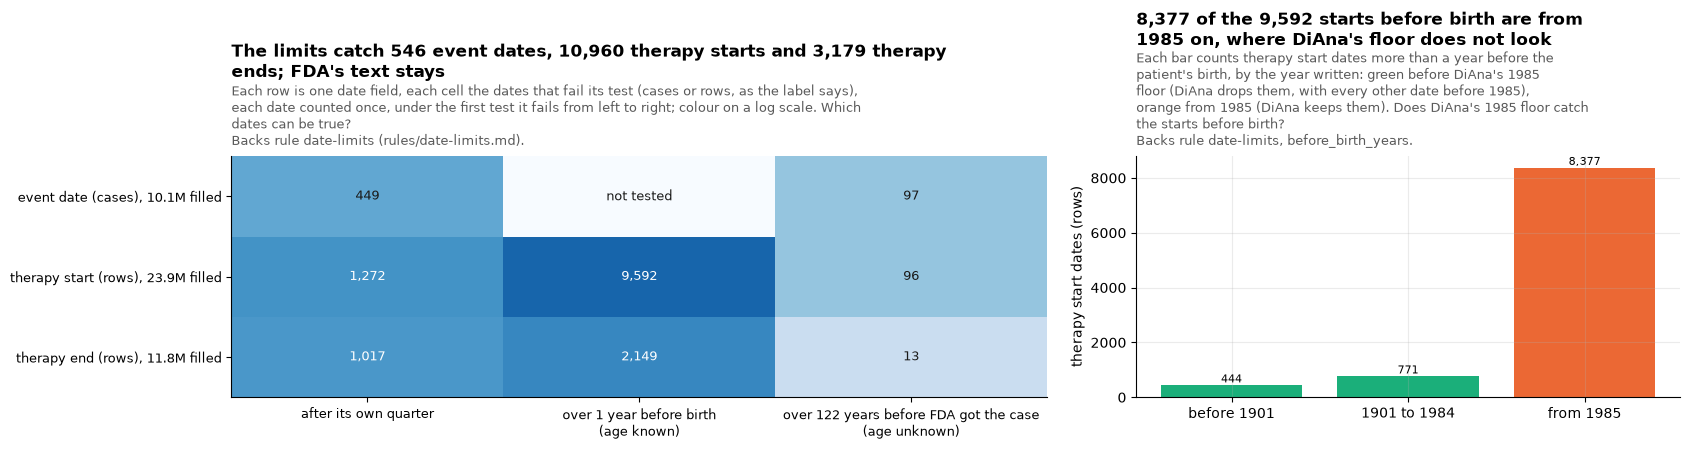

event date (cases): 10,058,940 filled; caught 546 (449 after their quarter, 0 before birth, 97 by the 122-year floor).
therapy start (rows): 23,861,377 filled; caught 10,960 (1,272 after their quarter, 9,592 before birth, 96 by the 122-year floor).
therapy end (rows): 11,768,712 filled; caught 3,179 (1,017 after their quarter, 2,149 before birth, 13 by the 122-year floor).
Therapy starts before birth: 444 before 1901, 771 from 1901 to 1984, 8,377 from 1985.
The 122-year floor where the age is not known catches 96 therapy starts and 13 ends.
  checked twice: event date (cases) with no clean value = 546
  checked twice: therapy start (rows) with no clean value = 10,960
  checked twice: therapy end (rows) with no clean value = 3,179


  checked twice: therapy starts more than a year before birth (rows) = 9,592


  checked twice: event dates after their own quarter (cases) = 449


In [2]:
# Each date, first test failed: the ceiling, then the floor (birth where the age is known, else 122 years).
EV_YEAR = "CASE WHEN k.event_dt_prec_T IS NOT NULL THEN CAST(left(k.event_dt, 4) AS INT) END"
con.execute(f"""CREATE OR REPLACE TEMP TABLE limit_T AS
WITH t AS (
  SELECT t.*, k.age_years_T, k.init_year_T, floor(coalesce({EV_YEAR}, k.init_year_T) - k.age_years_T) AS born_T
  FROM ther_k_T t JOIN kept_T k USING (era_T, primaryid, quarter_T))
SELECT 'event date (cases)' AS field_T, event_dt AS raw_T, event_dt_prec_T AS prec_T,
       event_dt > left(quarter_end_T, length(event_dt)) AS ceiling_T,
       NULL::BOOLEAN AS birth_T,
       CAST(left(event_dt, 4) AS INT) < init_year_T - {MAX_AGE} AS oldest_T
FROM kept_T WHERE event_dt IS NOT NULL
UNION ALL
SELECT 'therapy start (rows)', start_dt, start_dt_prec_T, start_dt > left(quarter_end_T, length(start_dt)),
       CASE WHEN age_years_T >= 0 THEN CAST(left(start_dt, 4) AS INT) < born_T - {BEFORE_BIRTH} END,
       CASE WHEN NOT coalesce(age_years_T >= 0, false) THEN CAST(left(start_dt, 4) AS INT) < init_year_T - {MAX_AGE} END
FROM t WHERE start_dt IS NOT NULL
UNION ALL
SELECT 'therapy end (rows)', end_dt, end_dt_prec_T, end_dt > left(quarter_end_T, length(end_dt)),
       CASE WHEN age_years_T >= 0 THEN CAST(left(end_dt, 4) AS INT) < born_T - {BEFORE_BIRTH} END,
       CASE WHEN NOT coalesce(age_years_T >= 0, false) THEN CAST(left(end_dt, 4) AS INT) < init_year_T - {MAX_AGE} END
FROM t WHERE end_dt IS NOT NULL""")
TESTS = [
    "after its own quarter",
    f"over {BEFORE_BIRTH} year before birth (age known)",
    f"over {MAX_AGE} years before FDA got the case (age unknown)",
]
L = (
    q(f"""SELECT field_T, count(*) filled,
  count(*) FILTER (WHERE ceiling_T) "{TESTS[0]}",
  count(*) FILTER (WHERE NOT ceiling_T AND birth_T) "{TESTS[1]}",
  count(*) FILTER (WHERE NOT ceiling_T AND NOT coalesce(birth_T, false) AND oldest_T) "{TESTS[2]}",
  count(*) FILTER (WHERE prec_T IS NULL) "no clean value in the release"
  FROM limit_T GROUP BY 1""")
    .set_index("field_T")
    .loc[["event date (cases)", "therapy start (rows)", "therapy end (rows)"]]
)
L["caught"] = L[TESTS].sum(axis=1)
born = (
    q(f"""SELECT CASE WHEN left(raw_T, 4) < '1901' THEN 'before 1901' WHEN left(raw_T, 4) < '{DIANA_FLOOR}' THEN '1901 to 1984'
                         ELSE 'from 1985' END band, count(*) n
             FROM limit_T WHERE field_T = 'therapy start (rows)' AND NOT ceiling_T AND birth_T GROUP BY 1""")
    .set_index("band")
    .n
)
born = born.reindex(["before 1901", "1901 to 1984", "from 1985"]).fillna(0).astype(int)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1.5, 1]})
M = L[TESTS].values.astype(float)
a1.imshow(np.log10(M + 1), cmap="Blues", aspect="auto", vmin=0, vmax=5)
a1.grid(False)
a1.set_xticks(range(len(TESTS)))
a1.set_xticklabels([t.replace(" (", "\n(") for t in TESTS], fontsize=9)
a1.set_yticks(range(len(L)))
a1.set_yticklabels(
    [f"{f}, {n / 1e6:.1f}M filled" for f, n in zip(L.index, L.filled, strict=True)], fontsize=9
)
for (i, j), v in np.ndenumerate(M):
    a1.text(
        j,
        i,
        "not tested" if (i == 0 and j == 1) else f"{v:,.0f}",
        ha="center",
        va="center",
        fontsize=9,
        color="white" if v >= 1e3 else "#1a1a19",
    )
title(
    a1,
    f"The limits catch {L.caught.iloc[0]:,} event dates, {L.caught.iloc[1]:,} therapy starts and {L.caught.iloc[2]:,} therapy ends; FDA's text stays",
    "Each row is one date field, each cell the dates that fail its test (cases or rows, as the label says), each date counted once, "
    "under the first test it fails from left to right; colour on a log scale.",
    "Which dates can be true?",
    backs="Backs rule date-limits (rules/date-limits.md).",
    width=104,
)
colors = [SERIES[2], SERIES[2], SERIES[1]]
label_bars(a2, a2.bar(born.index, born.values, color=colors))
a2.set_ylabel("therapy start dates (rows)")
title(
    a2,
    f"{born['from 1985']:,} of the {born.sum():,} starts before birth are from 1985 on, where DiAna's floor does not look",
    "Each bar counts therapy start dates more than a year before the patient's birth, by the year written: green before DiAna's 1985 floor "
    "(DiAna drops them, with every other date before 1985), orange from 1985 (DiAna keeps them).",
    "Does DiAna's 1985 floor catch the starts before birth?",
    backs="Backs rule date-limits, before_birth_years.",
    width=66,
)
plt.tight_layout()
plt.show()
for f in L.index:
    r = L.loc[f]
    print(
        f"{f}: {r.filled:,} filled; caught {r.caught:,} ({r[TESTS[0]]:,} after their quarter, {r[TESTS[1]]:,} before birth, {r[TESTS[2]]:,} by the {MAX_AGE}-year floor)."
    )
print(
    f"Therapy starts before birth: {born['before 1901']:,} before 1901, {born['1901 to 1984']:,} from 1901 to 1984, {born['from 1985']:,} from 1985."
)
print(
    f"The {MAX_AGE}-year floor where the age is not known catches {L.loc['therapy start (rows)', TESTS[2]]:,} therapy starts and {L.loc['therapy end (rows)', TESTS[2]]:,} ends."
)
for f in L.index:
    check(
        f"{f} with no clean value",
        int(L.loc[f, "caught"]),
        int(L.loc[f, "no clean value in the release"]),
    )
check(
    "therapy starts more than a year before birth (rows)",
    int(born.sum()),
    one(f"""SELECT count(*) FROM ther_latest_T t JOIN case_latest_T c USING (era_T, primaryid, quarter_T)
      WHERE c.dup_kept_T AND c.age_years_T >= 0
        AND make_date(TRY_CAST(substr(t.start_dt, 1, 4) AS INTEGER), 1, 1) < make_date(CAST(floor(coalesce(
              CASE WHEN c.event_dt_prec_T IS NOT NULL THEN TRY_CAST(substr(c.event_dt, 1, 4) AS INTEGER) END, c.init_year_T) - c.age_years_T) AS INTEGER) - {BEFORE_BIRTH}, 1, 1)
        AND strptime(rpad(t.start_dt, 8, '01'), '%Y%m%d') <= last_day(make_date(CAST(substr(t.quarter_T, 1, 4) AS INT), CAST(substr(t.quarter_T, 6, 1) AS INT) * 3, 1))"""),
)
check(
    "event dates after their own quarter (cases)",
    int(L.loc["event date (cases)", TESTS[0]]),
    one(f"""SELECT count(*) {kept_join}
      AND try_strptime(CASE length(c.event_dt) WHEN 4 THEN c.event_dt || '0101' WHEN 6 THEN c.event_dt || '01' ELSE c.event_dt END, '%Y%m%d')
          > last_day(make_date(CAST(substr(c.quarter_T, 1, 4) AS INT), CAST(substr(c.quarter_T, 6, 1) AS INT) * 3, 1))"""),
)

### Are the old therapy starts true?

A start from 1901 to 1984 is a decade or more before most reports. If these were typing slips, the years on the drug would be wild and the patients of any age; if they are long treatments, the patients should be old enough to have taken the drug that long. The charts take every therapy start from 1901 to 1984, inside the limits, whose case gives the age: the years from the start to the event (else to the year FDA first received the case), and the patient's age.

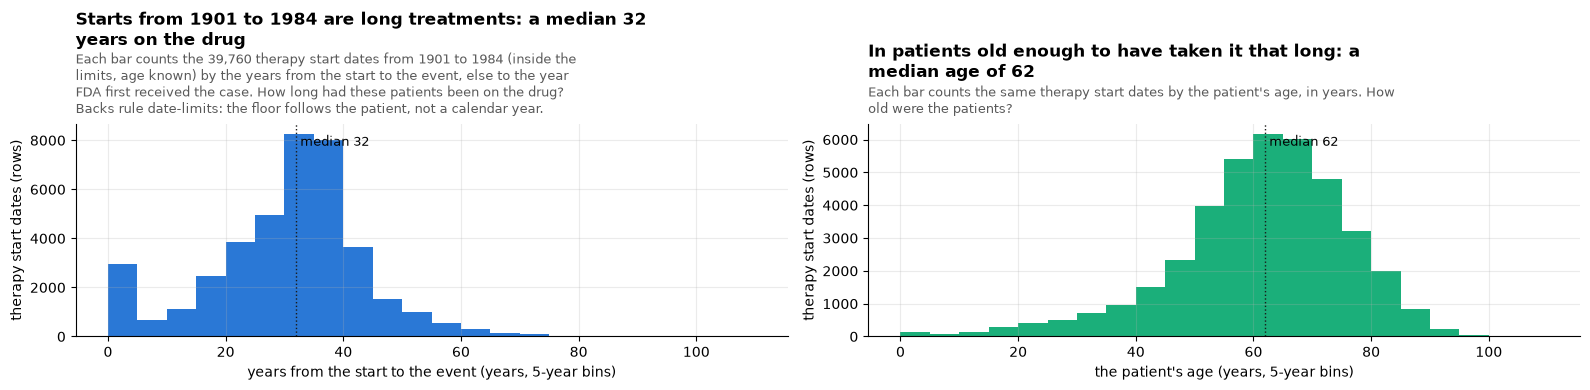

Therapy starts from 1901 to 1984 inside the limits with the age known: 39,760; median 32 years on the drug, median age 62.


  checked twice: therapy starts from 1901 to 1984 inside the limits, age known (rows) = 39,760


In [3]:
old = q(f"""SELECT coalesce({EV_YEAR}, k.init_year_T) - CAST(left(t.start_dt, 4) AS INT) AS years_T, k.age_years_T AS age_T
            FROM ther_k_T t JOIN kept_T k USING (era_T, primaryid, quarter_T)
            WHERE left(t.start_dt, 4) BETWEEN '1901' AND '1984' AND t.start_dt_prec_T IS NOT NULL AND k.age_years_T >= 0""")
med_years, med_age = old.years_T.median(), old.age_T.median()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 4))
for ax, col, med, colr, what in [
    (a1, "years_T", med_years, SERIES[0], "years from the start to the event"),
    (a2, "age_T", med_age, SERIES[2], "the patient's age"),
]:
    ax.hist(old[col].clip(upper=110), bins=range(0, 115, 5), color=colr)
    ax.axvline(med, color="#1a1a19", lw=1, ls=":")
    ax.text(med, ax.get_ylim()[1] * 0.95, f" median {med:.0f}", fontsize=9, va="top")
    ax.set_xlabel(f"{what} (years, 5-year bins)")
    ax.set_ylabel("therapy start dates (rows)")
title(
    a1,
    f"Starts from 1901 to 1984 are long treatments: a median {med_years:.0f} years on the drug",
    f"Each bar counts the {len(old):,} therapy start dates from 1901 to 1984 (inside the limits, age known) by the years from the start "
    "to the event, else to the year FDA first received the case.",
    "How long had these patients been on the drug?",
    backs="Backs rule date-limits: the floor follows the patient, not a calendar year.",
    width=80,
)
title(
    a2,
    f"In patients old enough to have taken it that long: a median age of {med_age:.0f}",
    "Each bar counts the same therapy start dates by the patient's age, in years.",
    "How old were the patients?",
    width=80,
)
plt.tight_layout()
plt.show()
print(
    f"Therapy starts from 1901 to 1984 inside the limits with the age known: {len(old):,}; median {med_years:.0f} years on the drug, median age {med_age:.0f}."
)
check(
    "therapy starts from 1901 to 1984 inside the limits, age known (rows)",
    len(old),
    one("""SELECT count(*) FROM ther_latest_T t JOIN case_latest_T c USING (era_T, primaryid, quarter_T)
      WHERE c.dup_kept_T AND c.age_years_T >= 0 AND t.start_dt_prec_T IS NOT NULL
        AND TRY_CAST(substr(t.start_dt, 1, 4) AS INTEGER) BETWEEN 1901 AND 1984"""),
)

### Why are the report and receipt dates not checked?

The ceiling would catch report dates too, but the report date is not one a time is worked out from, and it runs loose: the chart counts, for every date field, the values after the quarter that published them, and the report dates later than FDA's own receipt date.

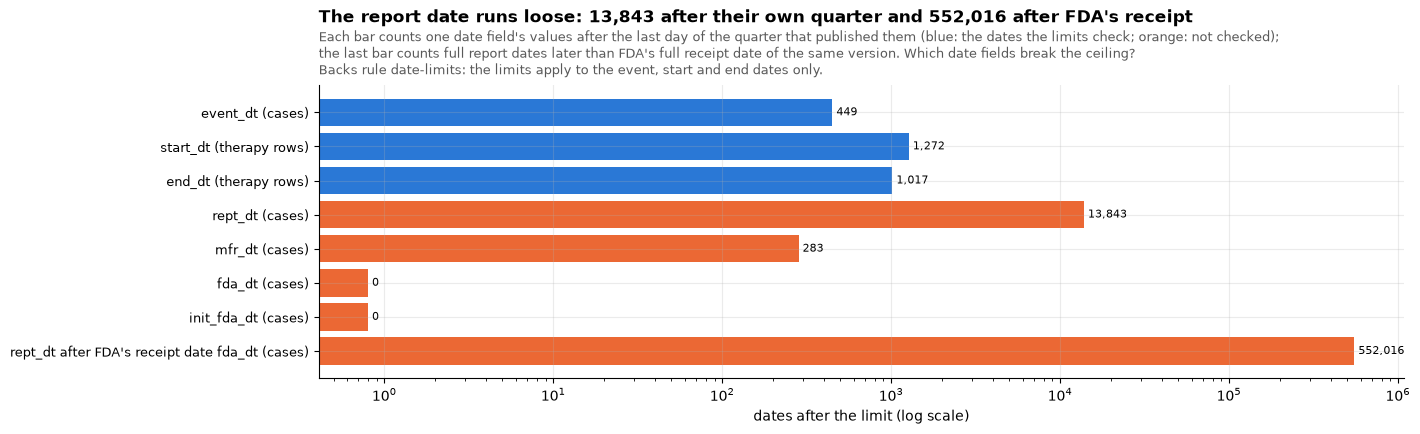

  checked twice: report dates after their own quarter (cases) = 13,843


  checked twice: report dates after FDA's receipt date (cases) = 552,016


In [4]:
FIELDS = [
    ("event_dt", "kept_T", "cases"),
    ("start_dt", "ther_k_T", "therapy rows"),
    ("end_dt", "ther_k_T", "therapy rows"),
    ("rept_dt", "kept_T", "cases"),
    ("mfr_dt", "kept_T", "cases"),
    ("fda_dt", "kept_T", "cases"),
    ("init_fda_dt", "kept_T", "cases"),
]
after = pd.Series(
    {
        f"{col} ({grain})": one(
            f"SELECT count(*) FROM {table} WHERE {col} > left(quarter_end_T, length({col}))"
        )
        for col, table, grain in FIELDS
    }
)
rept_after_fda = one(
    "SELECT count(*) FROM kept_T WHERE length(rept_dt) = 8 AND length(fda_dt) = 8 AND rept_dt > fda_dt"
)
fig, ax = plt.subplots(figsize=(14, 3.8))
y = np.arange(len(after) + 1)
vals = list(after.values) + [rept_after_fda]
names = list(after.index) + ["rept_dt after FDA's receipt date fda_dt (cases)"]
checked = [True, True, True, False, False, False, False, False]
bars = ax.barh(
    y, [max(v, 0.8) for v in vals], color=[SERIES[0] if c else SERIES[1] for c in checked]
)
for b, v in zip(bars, vals, strict=True):
    ax.text(b.get_width(), b.get_y() + b.get_height() / 2, f" {v:,}", va="center", fontsize=8)
ax.set_xscale("log")
ax.set_yticks(y)
ax.set_yticklabels(names, fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("dates after the limit (log scale)")
title(
    ax,
    f"The report date runs loose: {after['rept_dt (cases)']:,} after their own quarter and {rept_after_fda:,} after FDA's receipt",
    "Each bar counts one date field's values after the last day of the quarter that published them (blue: the dates the limits check; "
    "orange: not checked); the last bar counts full report dates later than FDA's full receipt date of the same version.",
    "Which date fields break the ceiling?",
    backs="Backs rule date-limits: the limits apply to the event, start and end dates only.",
    width=150,
)
plt.show()
check(
    "report dates after their own quarter (cases)",
    int(after["rept_dt (cases)"]),
    one(f"""SELECT count(*) {kept_join}
      AND try_strptime(CASE length(c.rept_dt) WHEN 4 THEN c.rept_dt || '0101' WHEN 6 THEN c.rept_dt || '01' ELSE c.rept_dt END, '%Y%m%d')
          > last_day(make_date(CAST(substr(c.quarter_T, 1, 4) AS INT), CAST(substr(c.quarter_T, 6, 1) AS INT) * 3, 1))"""),
)
check(
    "report dates after FDA's receipt date (cases)",
    rept_after_fda,
    one(
        f"SELECT count(*) {kept_join} AND try_strptime(c.rept_dt, '%Y%m%d') > try_strptime(c.fda_dt, '%Y%m%d') AND length(c.rept_dt) = 8 AND length(c.fda_dt) = 8"
    ),
)
_ = con.execute("DROP TABLE limit_T")

**What section 1 shows**, one item per chart:

- **What the limits catch.** *Shows:* in the default case set, the limits catch 546 event dates (97 under the 122-year floor, 449 after their quarter), 10,481 therapy starts (9,107 more than a year before birth, 102 under the 122-year floor where the age is not known, 1,272 after their quarter) and 3,152 therapy ends, out of millions filled; the release's clean columns are empty for exactly these. *Point:* almost every FAERS date can be true; the few that cannot are caught by tests a reader can say in a sentence. *So what:* rule `date-limits` stands as written; FDA's text stays beside every empty clean value.
- **Starts before birth, by DiAna's floor.** *Shows:* of the 9,107 therapy starts more than a year before the patient's birth, 438 are before 1901, 752 from 1901 to 1984 and 7,917 from 1985 on. *Point:* a calendar floor misses most impossible starts; the patient's birth catches them. *So what:* the floor follows the patient (`before_birth_years`), and 122 years is only the backstop where the age is not known, where it catches 102 starts.
- **Years on the drug, and age, for starts from 1901 to 1984.** *Shows:* 37,956 such starts inside the limits with the age known: a median 32 years on the drug, at a median age of 62. *Point:* these are long treatments in older patients, not typing slips. *So what:* we keep them, where DiAna's 1985 floor drops them all.
- **Dates after their own quarter, by field.** *Shows:* 13,843 report dates are after the quarter that published them, more than any other field, and 552,007 full report dates are later than FDA's receipt of the same version; the event, start and end dates break it 449, 1,272 and 1,017 times. *Point:* the report date is loose and nothing is worked out from it. *So what:* the limits check only the event, start and end dates.

## 2. Event dates padded to the 1st since 2021Q3

Legacy AERS wrote an event date known only to its month as the 1st of that month, and one known only to its year as 1 January (FDA's FAQ 3). FAERS kept partial dates as `yyyymm` and `yyyy` until 2021. The duplicates notebook (04) found event dates on the 1st coming back in 2021. The top chart follows the share of full event dates that fall on the 1st, quarter by quarter, with the 15th as a control: no one pads to the 15th. The bottom chart follows how many dates FDA writes partial, event dates against therapy start dates.

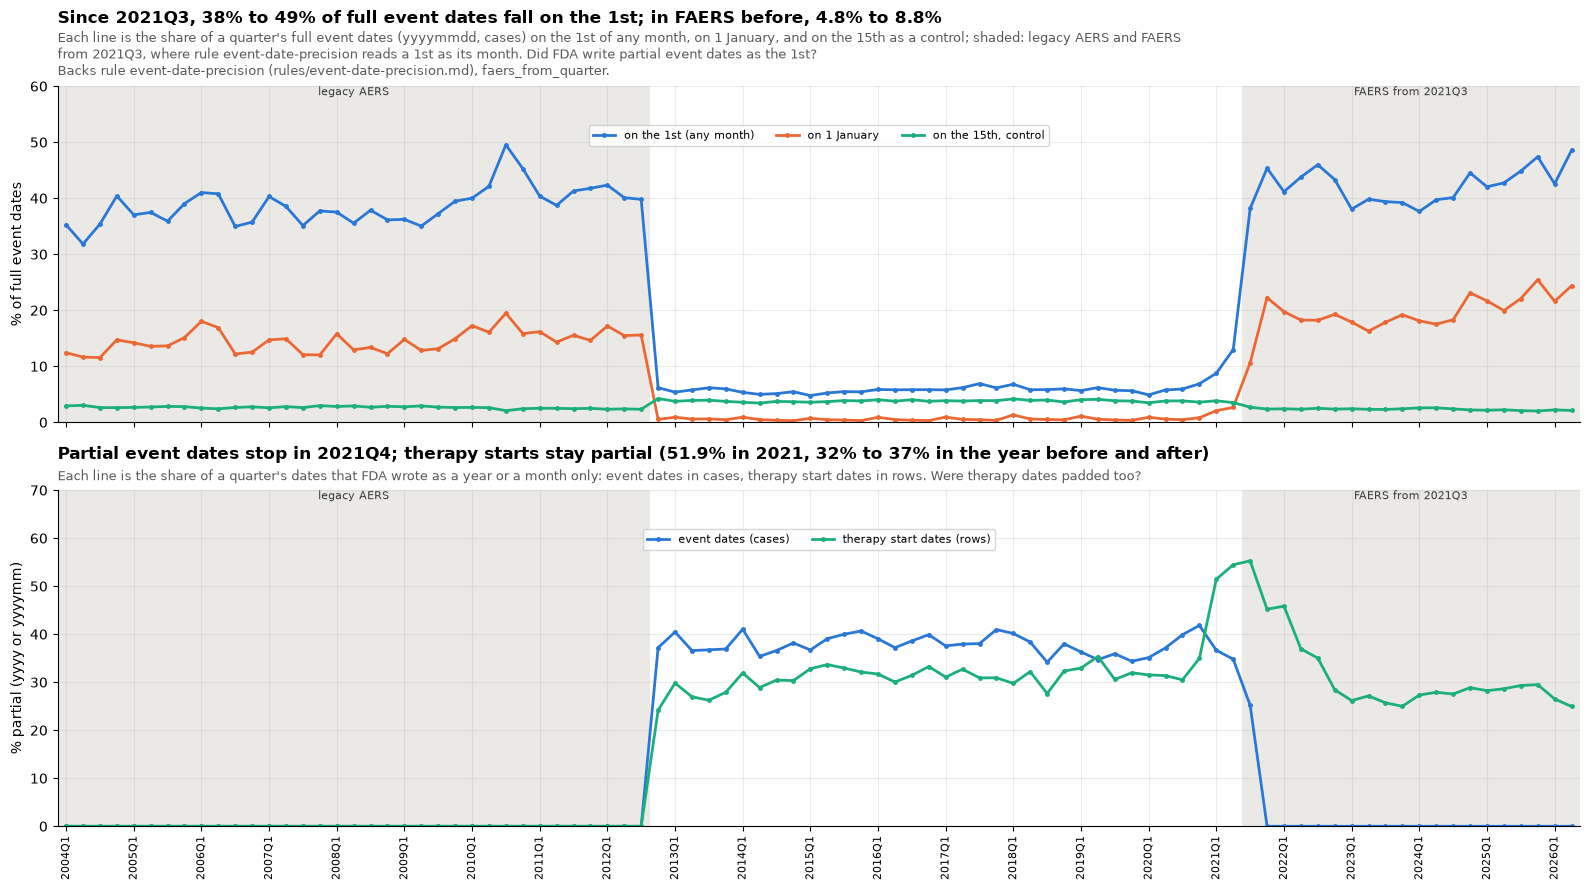

FAERS 2012Q4 to 2021Q1: 4.8% to 8.8% of full event dates on the 1st (median 5.8%); the 15th 3.8%. Legacy AERS: 32% to 50%.
Around the edge: 2020Q4 6.9%; 2021Q1 8.8%; 2021Q2 13.0%; 2021Q3 38.2%; 2021Q4 45.4%; 2022Q1 41.2%. From 2021Q4: 37.6% to 48.6%.
2021Q2 is a soft edge: about 7,069 more cases on the 1st than FAERS's own rate before; the rule starts at 2021Q3.
Therapy starts partial by year: 2018 30.5%, 2019 32.7%, 2020 32.1%, 2021 51.9%, 2022 37.0%, 2023 26.0%, 2024 27.9%.


,on the 1st (any month),on 1 January,"on the 15th, control",cases,% partial
quarter_T,,,,,
2020q4,6.9,0.8,3.6,165047,41.8
2021q1,8.8,2.1,3.8,153375,36.7
2021q2,13.0,2.7,3.5,150990,34.8
2021q3,38.2,10.6,2.7,224036,25.2
2021q4,45.4,22.2,2.4,161962,0.0
2022q1,41.2,19.8,2.4,166131,0.0


  checked twice: full event dates on the 1st, published from 2021Q4 (cases) = 1,224,002


In [5]:
P = (
    q(f"""SELECT quarter_T, count(*) n_all,
  count(*) FILTER (WHERE length(event_dt) < 8) n_partial,
  count(*) FILTER (WHERE length(event_dt) = 8) full_,
  count(*) FILTER (WHERE length(event_dt) = 8 AND right(event_dt, 2) = '{MONTH_DAY}') d1,
  count(*) FILTER (WHERE length(event_dt) = 8 AND right(event_dt, 4) = '{YEAR_DAY}') jan1,
  count(*) FILTER (WHERE length(event_dt) = 8 AND right(event_dt, 2) = '15') d15
  FROM kept_T WHERE event_dt IS NOT NULL GROUP BY 1""")
    .set_index("quarter_T")
    .reindex(QUARTERS)
)
SH = pd.DataFrame(
    {
        "on the 1st (any month)": 100 * P.d1 / P.full_,
        "on 1 January": 100 * P.jan1 / P.full_,
        "on the 15th, control": 100 * P.d15 / P.full_,
    }
)
partial = pd.DataFrame(
    {
        "event dates (cases)": 100 * P.n_partial / P.n_all,
        "therapy start dates (rows)": q("""SELECT quarter_T, 100 * avg((length(start_dt) < 8)::INT) p FROM ther_k_T
                                           WHERE start_dt IS NOT NULL GROUP BY 1""")
        .set_index("quarter_T")
        .p.reindex(QUARTERS),
    }
)
FULL_PAD = next(
    x for x in QUARTERS if x >= PAD_FROM and P.n_partial[x] == 0
)  # first quarter with no partial event date
on1 = SH["on the 1st (any month)"]
base_lo, base_hi, base_med = on1[BASE].min(), on1[BASE].max(), on1[BASE].median()
late = on1[[x for x in QUARTERS if x >= PAD_FROM]]
legacy = on1[[x for x in QUARTERS if x < "2012q4"]].dropna()
d15_med = SH["on the 15th, control"][BASE].median()
soft_extra = (on1[SOFT] - base_med) / 100 * P.full_[SOFT]
ther_year = (
    q("""SELECT left(quarter_T, 4)::INT yr, 100 * avg((length(start_dt) < 8)::INT) p FROM ther_k_T
                 WHERE start_dt IS NOT NULL GROUP BY 1 ORDER BY 1""")
    .set_index("yr")
    .p
)
pad_year = int(PAD_FROM[:4])
around = ther_year[[y for y in (pad_year - 1, pad_year + 1) if y in ther_year.index]]

fig, axes = plt.subplots(2, 1, figsize=(16, 9), sharex=True)
for i, c in enumerate(SH.columns):
    axes[0].plot(range(len(SH)), SH[c], color=SERIES[i], marker="o", ms=2.5, label=c)
axes[0].set_ylim(0, 60)
axes[0].set_ylabel("% of full event dates")
title(
    axes[0],
    f"Since {Q(PAD_FROM)}, {late.min():.0f}% to {late.max():.0f}% of full event dates fall on the 1st; in FAERS before, {base_lo:.1f}% to {base_hi:.1f}%",
    "Each line is the share of a quarter's full event dates (yyyymmdd, cases) on the 1st of any month, on 1 January, and on the 15th "
    f"as a control; shaded: legacy AERS and FAERS from {Q(PAD_FROM)}, where rule event-date-precision reads a 1st as its month.",
    "Did FDA write partial event dates as the 1st?",
    backs="Backs rule event-date-precision (rules/event-date-precision.md), faers_from_quarter.",
    width=175,
)
for i, c in enumerate(partial.columns):
    axes[1].plot(range(len(partial)), partial[c], color=SERIES[i * 2], marker="o", ms=2.5, label=c)
axes[1].set_ylim(0, 70)
axes[1].set_ylabel("% partial (yyyy or yyyymm)")
title(
    axes[1],
    f"Partial event dates stop in {Q(FULL_PAD)}; therapy starts stay partial ({ther_year[pad_year]:.1f}% in {pad_year}, {around.min():.0f}% to {around.max():.0f}% in the year before and after)",
    "Each line is the share of a quarter's dates that FDA wrote as a year or a month only: event dates in cases, therapy start dates in rows.",
    "Were therapy dates padded too?",
    width=175,
)
for ax in axes:
    shade(ax, "2004q1", "2012q3", "legacy AERS")
    shade(ax, PAD_FROM, QUARTERS[-1], f"FAERS from {Q(PAD_FROM)}")
    ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, 0.9), fontsize=8)
quarter_axis(axes[1])
plt.tight_layout()
plt.show()
edge = [x for x in QUARTERS if "2020q4" <= x <= QUARTERS[QUARTERS.index(FULL_PAD) + 1]]
print(
    f"FAERS {Q(BASE[0])} to {Q(BASE[-1])}: {base_lo:.1f}% to {base_hi:.1f}% of full event dates on the 1st (median {base_med:.1f}%); the 15th {d15_med:.1f}%. Legacy AERS: {legacy.min():.0f}% to {legacy.max():.0f}%."
)
print(
    "Around the edge: "
    + "; ".join(f"{Q(x)} {on1[x]:.1f}%" for x in edge)
    + f". From {Q(FULL_PAD)}: {on1[FULL_PAD:].min():.1f}% to {on1[FULL_PAD:].max():.1f}%."
)
print(
    f"{Q(SOFT)} is a soft edge: about {soft_extra:,.0f} more cases on the 1st than FAERS's own rate before; the rule starts at {Q(PAD_FROM)}."
)
print(
    "Therapy starts partial by year: "
    + ", ".join(f"{y} {v:.1f}%" for y, v in ther_year.loc[pad_year - 3 : pad_year + 3].items())
    + "."
)
display(
    SH.loc[edge]
    .round(1)
    .assign(
        cases=P.n_all[edge].astype(int),
        **{"% partial": partial["event dates (cases)"][edge].round(1)},
    )
)
check(
    f"full event dates on the 1st, published from {Q(FULL_PAD)} (cases)",
    int(P.d1[FULL_PAD:].sum()),
    one(f"""SELECT count(*) {kept_join} AND c.era_T = 'faers' AND c.quarter_T >= '{FULL_PAD}'
      AND day(try_strptime(c.event_dt, '%Y%m%d')) = 1"""),
)

### What reading a 1st as its month costs, and what it saves

A padded date cannot be told from a true 1st. Rule `event-date-precision` therefore reads every full event date on the 1st, in legacy AERS and in FAERS from 2021Q3, as known to its month, and 1 January as known to its year. That costs the true 1sts in those versions: they lose their day. It saves the padded dates from passing as exact days. The chart sizes both from FAERS's own share of 1sts before the padding, and from chance (one day in 30.4). FAERS's own share is above chance, so some padding was there before 2021 too, and the padded counts at FAERS's own rate are floors.

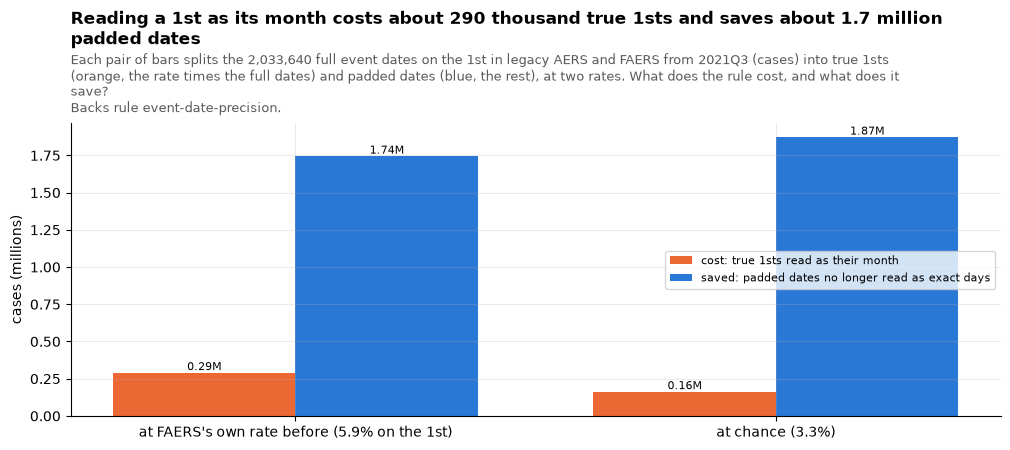

Full event dates in the padding windows: 4,932,473; on the 1st: 2,033,640. FAERS's own share before: 5.88% (2012Q4 to 2021Q1).
FAERS from 2021Q4: 1,224,002 on the 1st of 2,872,852; padded at FAERS's own rate about 1,055,108 (a floor), at chance about 1,129,617.
The duplicate rules compare FDA's own event_dt, never event_dt_T, so this rule moves no group and no kept case (rules/event-date-precision.md).
In the release: 1,158,738 full event dates read to the month, 874,794 to the year.


  checked twice: full event dates the rule reads to the month or year (cases) = 2,033,532


In [6]:
WIN = con.execute(f"""SELECT count(*) FILTER (WHERE length(event_dt) = 8),
                               count(*) FILTER (WHERE length(event_dt) = 8 AND right(event_dt, 2) = '{MONTH_DAY}'),
                               count(*) FILTER (WHERE era_T = 'faers' AND quarter_T >= '{FULL_PAD}' AND length(event_dt) = 8),
                               count(*) FILTER (WHERE era_T = 'faers' AND quarter_T >= '{FULL_PAD}' AND length(event_dt) = 8 AND right(event_dt, 2) = '{MONTH_DAY}')
                        FROM kept_T WHERE era_T = 'legacy' OR quarter_T >= '{PAD_FROM}'""").fetchone()
full_w, on1_w, full_late, on1_late = WIN
base_rate = P.d1[BASE].sum() / P.full_[BASE].sum()
chance = 12 / YEAR  # one day of a month, on average
OWN = "FAERS's own rate before"
cost = {OWN: base_rate * full_w, "chance": chance * full_w}
gain = {k: on1_w - v for k, v in cost.items()}
fig, ax = plt.subplots(figsize=(12, 3.8))
x = np.arange(2)
w = 0.38
label_bars(
    ax,
    ax.bar(
        x - w / 2,
        [cost[k] / 1e6 for k in cost],
        w,
        color=SERIES[1],
        label="cost: true 1sts read as their month",
    ),
    "{:.2f}M",
)
label_bars(
    ax,
    ax.bar(
        x + w / 2,
        [gain[k] / 1e6 for k in gain],
        w,
        color=SERIES[0],
        label="saved: padded dates no longer read as exact days",
    ),
    "{:.2f}M",
)
ax.set_xticks(x)
ax.set_xticklabels(
    [
        f"at FAERS's own rate before ({100 * base_rate:.1f}% on the 1st)",
        f"at chance ({100 * chance:.1f}%)",
    ]
)
ax.set_ylabel("cases (millions)")
ax.legend(fontsize=8)
title(
    ax,
    f"Reading a 1st as its month costs about {cost[OWN] / 1e3:,.0f} thousand true 1sts and saves about {gain[OWN] / 1e6:.1f} million padded dates",
    f"Each pair of bars splits the {on1_w:,} full event dates on the 1st in legacy AERS and FAERS from {Q(PAD_FROM)} (cases) into true 1sts "
    "(orange, the rate times the full dates) and padded dates (blue, the rest), at two rates.",
    "What does the rule cost, and what does it save?",
    backs="Backs rule event-date-precision.",
    width=130,
)
plt.show()
late_floor, late_chance = on1_late - base_rate * full_late, on1_late - chance * full_late
print(
    f"Full event dates in the padding windows: {full_w:,}; on the 1st: {on1_w:,}. FAERS's own share before: {100 * base_rate:.2f}% ({Q(BASE[0])} to {Q(BASE[-1])})."
)
print(
    f"FAERS from {Q(FULL_PAD)}: {on1_late:,} on the 1st of {full_late:,}; padded at FAERS's own rate about {late_floor:,.0f} (a floor), at chance about {late_chance:,.0f}."
)
print(
    "The duplicate rules compare FDA's own event_dt, never event_dt_T, so this rule moves no group and no kept case (rules/event-date-precision.md)."
)
read = con.execute("""SELECT count(*) FILTER (WHERE event_dt_prec_T = 6), count(*) FILTER (WHERE event_dt_prec_T = 4)
                      FROM kept_T WHERE length(event_dt) = 8""").fetchone()
print(f"In the release: {read[0]:,} full event dates read to the month, {read[1]:,} to the year.")
check(
    "full event dates the rule reads to the month or year (cases)",
    read[0] + read[1],
    one(f"""SELECT count(*) {kept_join} AND length(c.event_dt) = 8 AND substr(c.event_dt, 7, 2) = '{MONTH_DAY}'
          AND (c.era_T = 'legacy' OR c.qnum_T >= {PAD_FROM[:4]}{PAD_FROM[-1]})
          AND c.event_dt <= strftime(last_day(make_date(CAST(substr(c.quarter_T, 1, 4) AS INT), CAST(substr(c.quarter_T, 6, 1) AS INT) * 3, 1)), '%Y%m%d')
          AND NOT coalesce(TRY_CAST(substr(c.event_dt, 1, 4) AS INTEGER) < c.init_year_T - {MAX_AGE}, false)"""),
)

**What section 2 shows**, one item per chart:

- **Full event dates on the 1st, by quarter.** *Shows:* in cases with a full event date: FAERS 2012Q4 to 2021Q1 put 4.8% to 8.8% on the 1st a quarter (median 5.8%), the 15th 3.8%; legacy AERS 32% to 50%. Then 2021Q1 8.8%, 2021Q2 13.0%, 2021Q3 38.2%; from 2021Q4 on, 37.6% to 48.6%. 2021Q2 is a soft edge, about 7,100 cases above FAERS's own rate. *Point:* from 2021Q3 FDA writes a month-only date as the 1st and a year-only date as 1 January, as legacy AERS did. *So what:* rule `event-date-precision` reads a 1st as its month, and 1 January as its year, in legacy AERS and from 2021Q3 (`faers_from_quarter`); the soft edge stays read as written, since most of its 1sts are true.
- **Partial dates, event against therapy start.** *Shows:* partial event dates vanish in 2021Q4; therapy starts stay partial throughout, at 51.9% in 2021 against 32% to 37% in the year before and after. *Point:* only the event date was padded; therapy dates were not, though 2021 is an odd year for them too. *So what:* the rule acts on event dates only.
- **What the rule costs and saves.** *Shows:* of the 2,033,630 full event dates on the 1st in the padding windows, about 290,000 are true 1sts at FAERS's own rate before (5.9%), and about 1.74 million are padded. In FAERS from 2021Q4 alone, about 1.06 million are padded at that rate, a floor: at chance (3.3%) it is about 1.13 million. *Point:* reading a 1st as its month loses a day on a few hundred thousand true dates and stops well over a million padded dates passing as exact days. *So what:* the rule reads 2,033,522 full event dates to the month or year; the duplicate rules read FDA's own date, so the kept set does not move.

## 3. Time to onset

**What it is.** How long after a drug was started the reaction began, in days: the event date less the drug's first dose, plus one, so a reaction on the first day of treatment is day 1, as E2B(R3) counts it (G.k.9.i.3.1: "the date of the first day of administration should be counted as Day 1").

**One value per drug.** A case has one event date, but each drug its own start: a case reporting three drugs gives three times to onset. The same person at another time is another case. FDA writes one therapy line per regimen, so a drug can have several lines; rule `time-to-onset` counts from the drug's earliest start known to the day, its first dose.

**Why a value of 0 or less is emptied.** It is not an onset: the event came before the drug. FAERS gives one event date per case, not per reaction, so a case with a rash in January, a drug started in February and liver injury in March reads as a negative onset for the liver injury. DiAna's code empties a value of 0 or less only for events before 2013, because FDA padded dates then (`Cleaning_script.R`, line 530):

```r
Ther <- Ther[, time_to_onset := ifelse(is.na(time_to_onset) | ( time_to_onset<=0 & event_dt<=20121231), NA, time_to_onset)]
```

DiAna's documentation describes something else (all dates ending in 01 before 2013 set to empty). Section 2 found the padding back from 2021Q3, so the left chart asks whether a padded date makes a reaction look as if it came before the drug, with FAERS to 2021Q2 as the control. The right chart asks what one value per drug, from its earliest start, changes. Both read FDA's own dates, both full.

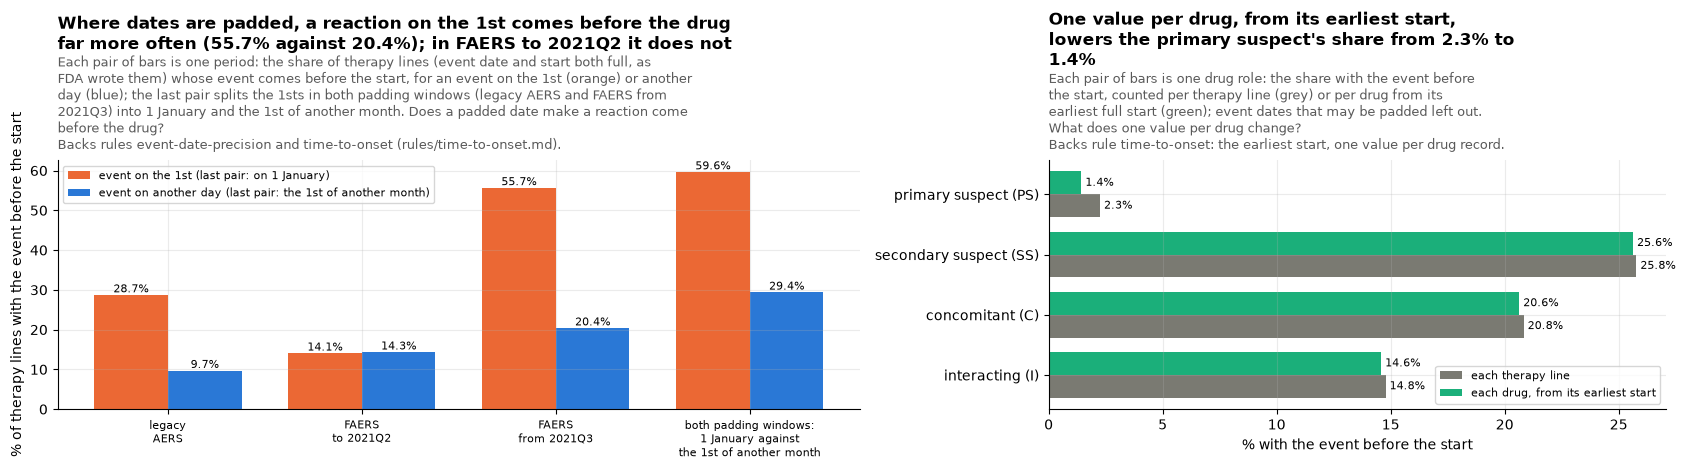

Therapy lines with both dates full: 12,913,487 in 5,356,910 cases; event before the start: 2,552,116 (19.8%).
Share of therapy lines with the event before the start, event on the 1st against another day: legacy AERS 28.7% against 9.7%; FAERS to 2021Q2 14.1% against 14.3%; FAERS from 2021Q3 55.7% against 20.4%; in both padding windows, 1 January 59.6% against the 1st of another month 29.4%.


  checked twice: therapy lines with both dates full = 12,913,487


  checked twice: therapy lines with the event before the start = 2,552,116


In [7]:
con.execute(f"""CREATE OR REPLACE TEMP TABLE tto_T AS
SELECT k.era_T, k.quarter_T, k.primaryid, t.dsg_drug_seq AS drug_seq, k.event_dt, t.start_dt, d.role_cod,
  k.event_dt < t.start_dt AS before_T,
  (k.era_T = 'legacy' OR k.quarter_T >= '{PAD_FROM}') AND right(k.event_dt, 2) = '{MONTH_DAY}' AS maybe_padded_T,
  CASE WHEN k.era_T = 'legacy' THEN '1 legacy AERS' WHEN k.quarter_T < '{PAD_FROM}' THEN '2 FAERS to {Q(SOFT)}' ELSE '3 FAERS from {Q(PAD_FROM)}' END AS period_T,
  CASE WHEN right(k.event_dt, 4) = '{YEAR_DAY}' THEN '1 January' WHEN right(k.event_dt, 2) = '{MONTH_DAY}' THEN 'the 1st of another month'
       ELSE 'another day' END AS day_T
FROM kept_T k JOIN ther_k_T t USING (era_T, primaryid, quarter_T)
LEFT JOIN (SELECT DISTINCT era_T, primaryid, quarter_T, drug_seq, role_cod FROM drug_k_T) d   -- one role per drug record
       ON d.era_T = t.era_T AND d.primaryid = t.primaryid AND d.quarter_T = t.quarter_T AND d.drug_seq = t.dsg_drug_seq
WHERE length(k.event_dt) = 8 AND length(t.start_dt) = 8""")
by = q(
    """SELECT period_T, day_T <> 'another day' AS on_1st, count(*) n, 100 * avg(before_T::INT) pct FROM tto_T GROUP BY ALL"""
)
P3 = by.pivot(index="period_T", columns="on_1st", values="pct")
jan = (
    q("""SELECT day_T, 100 * avg(before_T::INT) pct FROM tto_T WHERE maybe_padded_T GROUP BY 1""")
    .set_index("day_T")
    .pct
)
ROLES = ["PS", "SS", "C", "I"]
line_vs_drug = q("""WITH full_ AS (SELECT * FROM tto_T WHERE NOT maybe_padded_T),
  per_drug AS (SELECT era_T, primaryid, quarter_T, drug_seq, any_value(role_cod) role_cod, any_value(event_dt) < min(start_dt) AS before_T
               FROM full_ GROUP BY ALL)
SELECT role_cod, 'each therapy line' how, 100 * avg(before_T::INT) pct, count(*) n FROM full_ GROUP BY ALL
UNION ALL SELECT role_cod, 'each drug, from its earliest start', 100 * avg(before_T::INT), count(*) FROM per_drug GROUP BY ALL""")
LD = line_vs_drug.pivot(index="role_cod", columns="how", values="pct").reindex(ROLES)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
x = np.arange(len(P3) + 1)
w = 0.38
left = list(P3[True]) + [jan["1 January"]]
right = list(P3[False]) + [jan["the 1st of another month"]]
label_bars(
    a1,
    a1.bar(x - w / 2, left, w, color=SERIES[1], label="event on the 1st (last pair: on 1 January)"),
    "{:.1f}%",
)
label_bars(
    a1,
    a1.bar(
        x + w / 2,
        right,
        w,
        color=SERIES[0],
        label="event on another day (last pair: the 1st of another month)",
    ),
    "{:.1f}%",
)
a1.set_xticks(x)
a1.set_xticklabels(
    [p[2:].replace(" ", "\n", 1) for p in P3.index]
    + ["both padding windows:\n1 January against\nthe 1st of another month"],
    fontsize=8,
)
a1.set_ylabel("% of therapy lines with the event before the start")
a1.legend(fontsize=8, loc="upper left")
title(
    a1,
    f"Where dates are padded, a reaction on the 1st comes before the drug far more often ({P3.loc[P3.index[2], True]:.1f}% against {P3.loc[P3.index[2], False]:.1f}%); in FAERS to {Q(SOFT)} it does not",
    "Each pair of bars is one period: the share of therapy lines (event date and start both full, as FDA wrote them) whose event "
    "comes before the start, for an event on the 1st (orange) or another day (blue); the last pair splits the 1sts in both padding "
    f"windows (legacy AERS and FAERS from {Q(PAD_FROM)}) into 1 January and the 1st of another month.",
    "Does a padded date make a reaction come before the drug?",
    backs="Backs rules event-date-precision and time-to-onset (rules/time-to-onset.md).",
    width=96,
)
y = np.arange(len(LD))
label_bars(
    a2,
    a2.barh(y + w / 2, LD["each therapy line"], w, color=SERIES[6], label="each therapy line"),
    "{:.1f}%",
    horizontal=True,
)
label_bars(
    a2,
    a2.barh(
        y - w / 2,
        LD["each drug, from its earliest start"],
        w,
        color=SERIES[2],
        label="each drug, from its earliest start",
    ),
    "{:.1f}%",
    horizontal=True,
)
a2.set_yticks(y)
a2.set_yticklabels(
    ["primary suspect (PS)", "secondary suspect (SS)", "concomitant (C)", "interacting (I)"]
)
a2.invert_yaxis()
a2.set_xlabel("% with the event before the start")
a2.legend(fontsize=8, loc="lower right")
title(
    a2,
    f"One value per drug, from its earliest start, lowers the primary suspect's share from {LD.loc['PS', 'each therapy line']:.1f}% to {LD.loc['PS', 'each drug, from its earliest start']:.1f}%",
    "Each pair of bars is one drug role: the share with the event before the start, counted per therapy line (grey) or per drug from its "
    "earliest full start (green); event dates that may be padded left out.",
    "What does one value per drug change?",
    backs="Backs rule time-to-onset: the earliest start, one value per drug record.",
    width=70,
)
plt.tight_layout()
plt.show()
n_rows, n_before = (
    one("SELECT count(*) FROM tto_T"),
    one("SELECT count(*) FROM tto_T WHERE before_T"),
)
print(
    f"Therapy lines with both dates full: {n_rows:,} in {one('SELECT count(DISTINCT era_T || primaryid || quarter_T) FROM tto_T'):,} cases; event before the start: {n_before:,} ({100 * n_before / n_rows:.1f}%)."
)
print(
    "Share of therapy lines with the event before the start, event on the 1st against another day: "
    + "; ".join(f"{p[2:]} {P3.loc[p, True]:.1f}% against {P3.loc[p, False]:.1f}%" for p in P3.index)
    + f"; in both padding windows, 1 January {jan['1 January']:.1f}% against the 1st of another month {jan['the 1st of another month']:.1f}%."
)
check(
    "therapy lines with both dates full",
    n_rows,
    one("""SELECT count(*) FROM ther_k_T t JOIN kept_T k USING (era_T, primaryid, quarter_T)
      WHERE regexp_full_match(k.event_dt, '[0-9]{8}') AND regexp_full_match(t.start_dt, '[0-9]{8}')"""),
)
check(
    "therapy lines with the event before the start",
    n_before,
    one("""SELECT count(*) FROM ther_k_T t JOIN kept_T k USING (era_T, primaryid, quarter_T)
      WHERE length(k.event_dt) = 8 AND length(t.start_dt) = 8
        AND CAST(strptime(k.event_dt, '%Y%m%d') AS DATE) - CAST(strptime(t.start_dt, '%Y%m%d') AS DATE) + 1 <= 0"""),
)
_ = con.execute("DROP TABLE tto_T")

### What the release holds

`drug_onset_T` has one row per drug record: a case and its drug sequence number, however many rows FDA wrote for it. Its `time_to_onset_T` is empty unless the drug's earliest therapy start and the event date are both known to the day and inside the limits, the event is not before the first dose, and no start known only to its month or year could be earlier: a record with a start of `201905` and another of `20190520` may have begun on 1 May. The left chart puts each drug record of the default case set under the first reason it has no value, recomputed here apart from the build; the right chart shows the values for the suspect drugs.

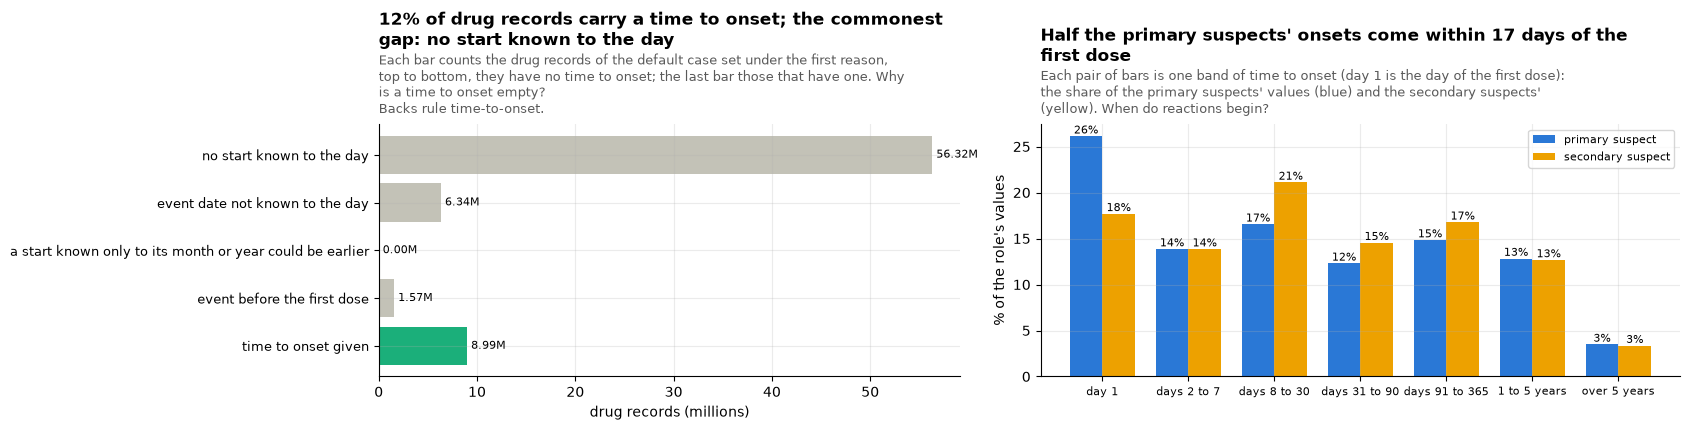

Drug records: 73,228,779; with a time to onset 8,994,287 (12.3%). With a start known to the day: 16,906,549; for 10,188 of these a start known only to its month or year could be earlier (3,407 of them with the event known to the day).
Median time to onset by role (days): PS 17, SS 26, C 63, I 12.


  checked twice: drug records with a time to onset = 8,994,287


  checked twice: drug records with a start known to the day = 16,906,549


  checked twice: drug records whose first dose may be before their earliest full start = 10,188


In [8]:
con.execute("""CREATE OR REPLACE TEMP TABLE first_T AS
WITH lines AS (SELECT era_T, primaryid, quarter_T, dsg_drug_seq AS drug_seq, start_dt, start_dt_T, start_dt_prec_T FROM ther_k_T),
f AS (SELECT era_T, primaryid, quarter_T, drug_seq, min(start_dt_T) AS first_T FROM lines WHERE start_dt_T IS NOT NULL GROUP BY ALL)
SELECT f.*, bool_or(CASE l.start_dt_prec_T
                      WHEN 6 THEN make_date(CAST(left(l.start_dt, 4) AS INT), CAST(substr(l.start_dt, 5, 2) AS INT), 1) <= f.first_T
                      WHEN 4 THEN make_date(CAST(left(l.start_dt, 4) AS INT), 1, 1) <= f.first_T
                      ELSE false END) AS earlier_T
FROM f JOIN lines l USING (era_T, primaryid, quarter_T, drug_seq) GROUP BY ALL""")
REASONS = [
    "no start known to the day",
    "event date not known to the day",
    "a start known only to its month or year could be earlier",
    "event before the first dose",
    "time to onset given",
]
ON = q(f"""WITH r AS (
  SELECT o.time_to_onset_T, d.role_cod,
    CASE WHEN f.first_T IS NULL THEN '{REASONS[0]}'
         WHEN k.event_dt_T IS NULL THEN '{REASONS[1]}'
         WHEN f.earlier_T THEN '{REASONS[2]}'
         WHEN k.event_dt_T < f.first_T THEN '{REASONS[3]}'
         ELSE '{REASONS[4]}' END AS reason_T,
    CASE WHEN f.first_T IS NOT NULL AND k.event_dt_T IS NOT NULL AND NOT f.earlier_T AND k.event_dt_T >= f.first_T
         THEN k.event_dt_T - f.first_T + {FIRST_DAY} END AS mine_T
  FROM onset_k_T o JOIN kept_T k USING (era_T, primaryid, quarter_T)
  LEFT JOIN first_T f USING (era_T, primaryid, quarter_T, drug_seq)
  LEFT JOIN (SELECT DISTINCT era_T, primaryid, quarter_T, drug_seq, role_cod FROM drug_k_T) d USING (era_T, primaryid, quarter_T, drug_seq))
SELECT reason_T, role_cod, count(*) n, count(time_to_onset_T) n_release, count(*) FILTER (WHERE mine_T IS DISTINCT FROM time_to_onset_T) differ
FROM r GROUP BY ALL""")
assert ON.differ.sum() == 0, "the recomputed time to onset differs from the release's"
RS = ON.groupby("reason_T").n.sum().reindex(REASONS)
bands = q(f"""SELECT d.role_cod, CASE WHEN o.time_to_onset_T = {FIRST_DAY} THEN 0 WHEN o.time_to_onset_T <= 7 THEN 1 WHEN o.time_to_onset_T <= 30 THEN 2
                     WHEN o.time_to_onset_T <= 90 THEN 3 WHEN o.time_to_onset_T <= 365 THEN 4 WHEN o.time_to_onset_T <= 5 * 365 THEN 5 ELSE 6 END band,
                     count(*) n
              FROM onset_k_T o JOIN (SELECT DISTINCT era_T, primaryid, quarter_T, drug_seq, role_cod FROM drug_k_T) d USING (era_T, primaryid, quarter_T, drug_seq)
              WHERE o.time_to_onset_T IS NOT NULL AND d.role_cod IN ('PS', 'SS') GROUP BY ALL""")
MED = (
    q("""SELECT d.role_cod, median(o.time_to_onset_T) m FROM onset_k_T o
           JOIN (SELECT DISTINCT era_T, primaryid, quarter_T, drug_seq, role_cod FROM drug_k_T) d USING (era_T, primaryid, quarter_T, drug_seq)
           WHERE o.time_to_onset_T IS NOT NULL GROUP BY 1""")
    .set_index("role_cod")
    .m
)
BAND = [
    "day 1",
    "days 2 to 7",
    "days 8 to 30",
    "days 31 to 90",
    "days 91 to 365",
    "1 to 5 years",
    "over 5 years",
]
B3 = (
    bands.pivot_table(index="band", columns="role_cod", values="n", aggfunc="sum")
    .reindex(range(7))
    .fillna(0)
)
B3 = 100 * B3 / B3.sum()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(17, 4.4), gridspec_kw={"width_ratios": [1, 1.1]})
y = np.arange(len(RS))
label_bars(
    a1, a1.barh(y, RS / 1e6, color=[SERIES[7]] * 4 + [SERIES[2]]), "{:.2f}M", horizontal=True
)
a1.set_yticks(y)
a1.set_yticklabels(REASONS, fontsize=9)
a1.invert_yaxis()
a1.set_xlabel("drug records (millions)")
given = int(RS[REASONS[4]])
gap = RS.drop(REASONS[4]).idxmax()
title(
    a1,
    f"{100 * given / RS.sum():.0f}% of drug records carry a time to onset; the commonest gap: {gap}",
    "Each bar counts the drug records of the default case set under the first reason, top to bottom, they have no time to onset; the last bar "
    "those that have one.",
    "Why is a time to onset empty?",
    backs="Backs rule time-to-onset.",
    width=80,
)
x = np.arange(7)
for i, role in enumerate(["PS", "SS"]):
    label_bars(
        a2,
        a2.bar(
            x + (i - 0.5) * w,
            B3[role],
            w,
            color=[SERIES[0], SERIES[3]][i],
            label={"PS": "primary suspect", "SS": "secondary suspect"}[role],
        ),
        "{:.0f}%",
    )
a2.set_xticks(x)
a2.set_xticklabels(BAND, fontsize=8)
a2.set_ylabel("% of the role's values")
a2.legend(fontsize=8)
title(
    a2,
    f"Half the primary suspects' onsets come within {MED['PS']:.0f} days of the first dose",
    "Each pair of bars is one band of time to onset (day 1 is the day of the first dose): the share of the primary suspects' values (blue) and "
    "the secondary suspects' (yellow).",
    "When do reactions begin?",
    width=84,
)
plt.tight_layout()
plt.show()
full_start = int(RS.drop(REASONS[0]).sum())
earlier = int(RS[REASONS[2]])
earlier_any = one(
    "SELECT count(*) FROM first_T f SEMI JOIN onset_k_T o USING (era_T, primaryid, quarter_T, drug_seq) WHERE f.earlier_T"
)
print(
    f"Drug records: {int(RS.sum()):,}; with a time to onset {given:,} ({100 * given / RS.sum():.1f}%). With a start known to the day: {full_start:,}; "
    f"for {earlier_any:,} of these a start known only to its month or year could be earlier ({earlier:,} of them with the event known to the day)."
)
print(
    "Median time to onset by role (days): "
    + ", ".join(f"{r} {MED[r]:.0f}" for r in ["PS", "SS", "C", "I"] if r in MED)
    + "."
)
check(
    "drug records with a time to onset", given, one("SELECT count(time_to_onset_T) FROM onset_k_T")
)
check(
    "drug records with a start known to the day",
    full_start,
    one("""SELECT count(*) FROM (SELECT DISTINCT era_T, primaryid, quarter_T, dsg_drug_seq FROM ther_latest_T WHERE start_dt_T IS NOT NULL) t
           SEMI JOIN case_dedup_T c USING (era_T, primaryid, quarter_T)
           SEMI JOIN drug_latest_T r ON r.era_T = t.era_T AND r.primaryid = t.primaryid AND r.quarter_T = t.quarter_T AND r.drug_seq = t.dsg_drug_seq"""),
)
check(
    "drug records whose first dose may be before their earliest full start",
    earlier_any,
    one("""WITH t AS (SELECT t.* FROM ther_latest_T t SEMI JOIN case_dedup_T c USING (era_T, primaryid, quarter_T)),
      f AS (SELECT era_T, primaryid, quarter_T, dsg_drug_seq, strftime(min(start_dt_T), '%Y%m%d') AS first_ FROM t WHERE start_dt_T IS NOT NULL GROUP BY ALL)
      SELECT count(*) FROM f WHERE EXISTS (SELECT 1 FROM t WHERE t.era_T = f.era_T AND t.primaryid = f.primaryid AND t.quarter_T = f.quarter_T
        AND t.dsg_drug_seq = f.dsg_drug_seq AND t.start_dt_prec_T IN (4, 6) AND left(t.start_dt, t.start_dt_prec_T) <= left(f.first_, t.start_dt_prec_T))
      AND EXISTS (SELECT 1 FROM drug_latest_T d WHERE d.era_T = f.era_T AND d.primaryid = f.primaryid AND d.quarter_T = f.quarter_T AND d.drug_seq = f.dsg_drug_seq)"""),
)
_ = con.execute("DROP TABLE first_T")

**What section 3 shows**, one item per chart:

- **Event before the start, by period and day.** *Shows:* in therapy lines with both dates full (12,913,305): legacy AERS 28.7% for an event on the 1st against 9.7% for other days; FAERS to 2021Q2 14.1% against 14.3%, the control; FAERS from 2021Q3 55.7% against 20.4%; and in both padding windows, 1 January 59.6% against the 1st of another month 29.4%. *Point:* a padded date pulls the reaction before the drug, most of all a year-only date written as 1 January; where FDA did not pad, the 1st behaves like any other day. *So what:* no time to onset from a date rule `event-date-precision` reads to the month or year; DiAna's rule, which looks only before 2013, misses all padding since 2021.
- **Per therapy line against per drug.** *Shows:* with event dates that cannot be padded, the primary suspect's event comes before the start on 2.3% of therapy lines and 1.4% of drugs counted from their earliest start; secondary suspects 25.8% and 25.6%, concomitant drugs 20.8% and 20.6%. *Point:* most remaining negatives are a later regimen of the same drug, or drugs started after the reaction. *So what:* rule `time-to-onset` gives one value per drug record, from its earliest start, and empties values of 0 or less.
- **Why a time to onset is empty.** *Shows:* of 73,228,322 drug records, 8,994,533 (12%) carry a time to onset; the recount here matches the release's `time_to_onset_T` on every record. For 10,188 of the 16.9 million records with a start known to the day, a start known only to its month or year could be earlier. *Point:* the value is missing mostly because FDA's therapy dates are, not because of the rule. *So what:* a time to onset is given only where it can be true.
- **Time to onset of the suspects.** *Shows:* half the primary suspects' values fall within 17 days of the first dose (secondary suspects 26). *Point:* the values have the shape a reader expects, with no pile of negatives or padded days. *So what:* `drug_onset_T` is ready for the explorer and the statistics to use.

## 4. Therapy duration

A therapy line can carry a start and an end date, FDA's duration with a unit (`dur`, `dur_cod`: YR, MON, WK, DAY, HR, MIN, SEC), both, or neither. E2B(R3) says the duration "will usually be computed from the start / end date" and is sent when the dates are not exact (G.k.4.r.6). Rule `therapy-duration` takes the days between the two clean dates (end less start, plus one) when both are known to the day and the end is not before the start, else FDA's number in its unit. It never fills a missing date from a duration, as DiAna does: a date made that way would look like one the reporter gave.

The left chart shows what a therapy line gives; the right how FDA's number compares with the dates where a line gives both. A duration in hours or minutes is compared there with calendar days: a 30-minute infusion on one day counts as day 1 by the dates and as 0.02 days by FDA's number, so those units agree poorly by construction.

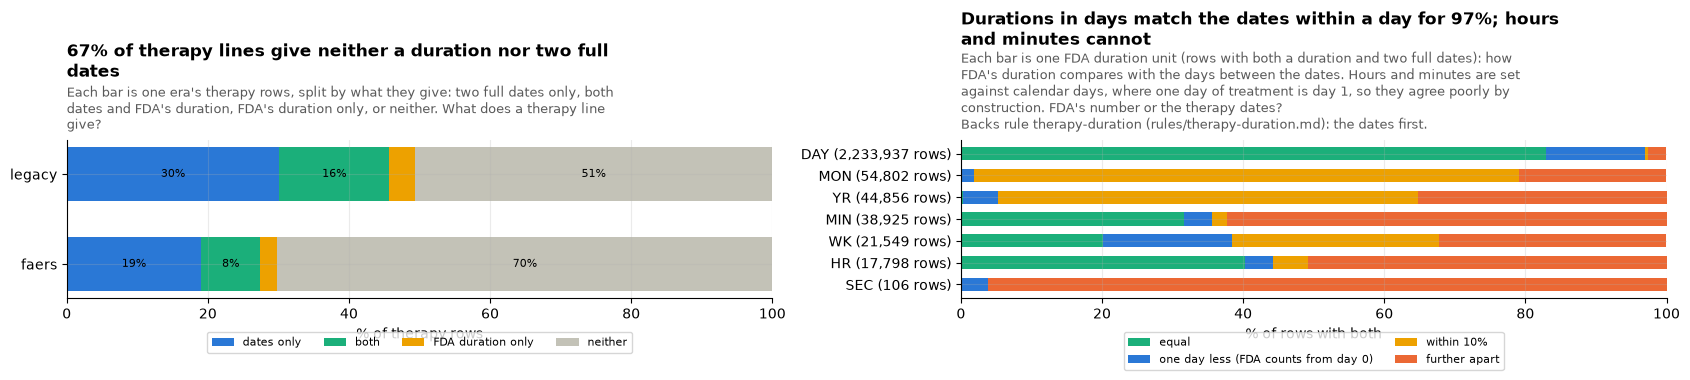

Therapy rows with both dates in full: 7,675,015. With FDA's duration: 3,071,146. With both: 2,413,515, agreeing within a day in 2,256,413 (93.5%).
End date before start date: 26,249 rows (25,593 of them legacy). DiAna's fill would write 10,354 start dates and 70,834 end dates nobody reported. Units outside FDA's list (CYC, TOT, spellings): 396 rows.
Agreement for hours and minutes: HR 44% within a day, MIN 36% within a day.


  checked twice: therapy rows with both dates in full = 7,675,015


  checked twice: therapy rows ending before they start = 26,249


In [9]:
unit_case = (
    "CASE dur_cod "
    + " ".join(f"WHEN '{u}' THEN {float(d)!r}" for u, d in UNIT_DAYS.items())
    + " END"
)
con.execute(f"""CREATE OR REPLACE TEMP TABLE dur_T AS
SELECT t.era_T, t.dur_cod, t.start_dt, t.end_dt, t.start_dt_T, t.end_dt_T, t.dur_days_T, k.age_years_T,
  CASE WHEN regexp_full_match(trim(t.dur), '[0-9]+[.]?[0-9]*|[.][0-9]+') THEN CAST(trim(t.dur) AS DOUBLE) * {unit_case} END AS fda_days_T,
  CASE WHEN length(t.start_dt) = 8 AND length(t.end_dt) = 8
       THEN CAST(try_strptime(t.end_dt, '%Y%m%d') AS DATE) - CAST(try_strptime(t.start_dt, '%Y%m%d') AS DATE) + 1 END AS date_days_T
FROM ther_k_T t JOIN kept_T k USING (era_T, primaryid, quarter_T)""")
have = (
    q("""SELECT era_T, CASE WHEN date_days_T IS NOT NULL AND fda_days_T IS NOT NULL THEN 'both'
                              WHEN date_days_T IS NOT NULL THEN 'dates only' WHEN fda_days_T IS NOT NULL THEN 'FDA duration only' ELSE 'neither' END what, count(*) n
            FROM dur_T GROUP BY ALL""")
    .pivot(index="era_T", columns="what", values="n")
    .reindex(columns=["dates only", "both", "FDA duration only", "neither"])
    .fillna(0)
)
HOW = ["equal", "one day less (FDA counts from day 0)", "within 10%", "further apart"]
agree = (
    q("""SELECT dur_cod, CASE WHEN fda_days_T = date_days_T THEN 'equal' WHEN fda_days_T = date_days_T - 1 THEN 'one day less (FDA counts from day 0)'
                                WHEN abs(fda_days_T - date_days_T) <= 0.1 * date_days_T THEN 'within 10%' ELSE 'further apart' END how, count(*) n
             FROM dur_T WHERE fda_days_T IS NOT NULL AND date_days_T > 0 GROUP BY ALL""")
    .pivot(index="dur_cod", columns="how", values="n")
    .fillna(0)
    .reindex(columns=HOW, fill_value=0)
)
agree = agree.loc[agree.sum(axis=1).sort_values().index]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(17, 4.2))
S4 = 100 * have.div(have.sum(axis=1), axis=0)
left = np.zeros(len(S4))
for c, color in zip(S4.columns, [SERIES[0], SERIES[2], SERIES[3], SERIES[7]], strict=True):
    a1.barh(S4.index, S4[c], left=left, color=color, label=c, height=0.6)
    for i, (v, start) in enumerate(zip(S4[c], left, strict=True)):
        if v > 4:
            a1.text(start + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=8)
    left += S4[c].values
a1.set_xlim(0, 100)
a1.set_xlabel("% of therapy rows")
neither = 100 * have["neither"].sum() / have.values.sum()
title(
    a1,
    f"{neither:.0f}% of therapy lines give neither a duration nor two full dates",
    "Each bar is one era's therapy rows, split by what they give: two full dates only, both dates and FDA's duration, FDA's duration only, or neither.",
    "What does a therapy line give?",
    width=86,
)
a1.legend(ncol=4, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.18))
A4 = 100 * agree.div(agree.sum(axis=1), axis=0)
left = np.zeros(len(A4))
for c, color in zip(A4.columns, [SERIES[2], SERIES[0], SERIES[3], SERIES[1]], strict=True):
    a2.barh(
        [f"{u} ({n:,.0f} rows)" for u, n in zip(A4.index, agree.sum(axis=1), strict=True)],
        A4[c],
        left=left,
        color=color,
        label=c,
        height=0.6,
    )
    left += A4[c].values
a2.set_xlim(0, 100)
a2.set_xlabel("% of rows with both")
day_ok = A4.loc["DAY", HOW[:2]].sum()
title(
    a2,
    f"Durations in days match the dates within a day for {day_ok:.0f}%; hours and minutes cannot",
    "Each bar is one FDA duration unit (rows with both a duration and two full dates): how FDA's duration compares with the days between "
    "the dates. Hours and minutes are set against calendar days, where one day of treatment is day 1, so they agree poorly by construction.",
    "FDA's number or the therapy dates?",
    backs="Backs rule therapy-duration (rules/therapy-duration.md): the dates first.",
    width=86,
)
a2.legend(ncol=2, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.18))
plt.tight_layout()
plt.show()
F4 = con.execute("""SELECT count(*) FILTER (WHERE date_days_T IS NOT NULL), count(*) FILTER (WHERE fda_days_T IS NOT NULL),
    count(*) FILTER (WHERE date_days_T IS NOT NULL AND fda_days_T IS NOT NULL),
    count(*) FILTER (WHERE date_days_T IS NOT NULL AND fda_days_T IS NOT NULL AND abs(fda_days_T - date_days_T) <= 1),
    count(*) FILTER (WHERE date_days_T <= 0), count(*) FILTER (WHERE date_days_T <= 0 AND era_T = 'legacy'),
    count(*) FILTER (WHERE start_dt IS NULL AND length(end_dt) = 8 AND fda_days_T IS NOT NULL),
    count(*) FILTER (WHERE end_dt IS NULL AND length(start_dt) = 8 AND fda_days_T IS NOT NULL),
    count(*) FILTER (WHERE dur_cod IS NOT NULL AND dur_cod NOT IN ('YR', 'MON', 'WK', 'DAY', 'HR', 'MIN', 'SEC')) FROM dur_T""").fetchone()
print(
    f"Therapy rows with both dates in full: {F4[0]:,}. With FDA's duration: {F4[1]:,}. With both: {F4[2]:,}, agreeing within a day in {F4[3]:,} ({100 * F4[3] / F4[2]:.1f}%)."
)
print(
    f"End date before start date: {F4[4]:,} rows ({F4[5]:,} of them legacy). DiAna's fill would write {F4[6]:,} start dates and {F4[7]:,} end dates nobody reported. "
    f"Units outside FDA's list (CYC, TOT, spellings): {F4[8]:,} rows."
)
print(
    "Agreement for hours and minutes: "
    + ", ".join(
        f"{u} {A4.loc[u, HOW[:2]].sum():.0f}% within a day" for u in ["HR", "MIN"] if u in A4.index
    )
    + "."
)
check(
    "therapy rows with both dates in full",
    F4[0],
    one(
        "SELECT count(*) FROM ther_k_T WHERE regexp_full_match(start_dt, '[0-9]{8}') AND regexp_full_match(end_dt, '[0-9]{8}')"
    ),
)
check(
    "therapy rows ending before they start",
    F4[4],
    one(
        "SELECT count(*) FROM ther_k_T WHERE length(start_dt) = 8 AND length(end_dt) = 8 AND end_dt < start_dt"
    ),
)

### How long can a therapy have lasted?

No one can take a drug for longer than they have lived. Rule `therapy-duration` empties a duration longer than the patient's age plus a year (in a report about a child exposed in the womb, the mother's treatment starts before the birth), and, where the age is not known, one longer than 50 years. DiAna's only cap is 50 years for everyone. The left chart counts the durations each cap catches; the right shows what `dur_days_T` holds.

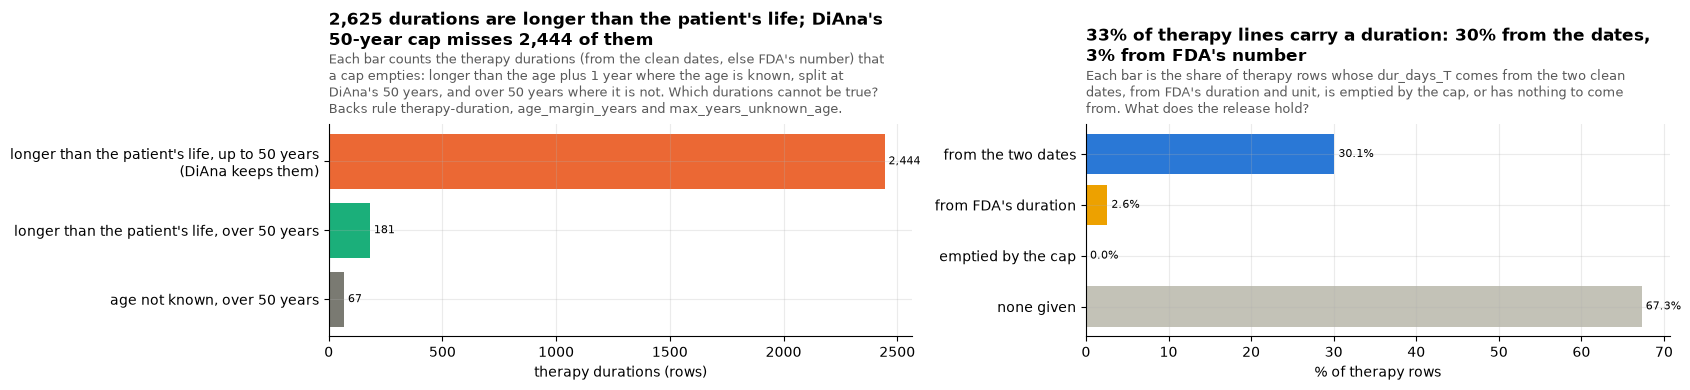

Durations over 50 years, any age: 393. Longer than the patient's life: 2,625 (2,444 up to 50 years, 181 over). Age not known and over 50 years: 67.
  checked twice: durations the cap empties (rows) = 2,692


  checked twice: therapy rows with a duration (rows) = 8,302,463


In [10]:
C = con.execute(f"""WITH c AS (
  SELECT *, coalesce(CASE WHEN end_dt_T >= start_dt_T THEN CAST(end_dt_T - start_dt_T + 1 AS DOUBLE) END, fda_days_T) AS days_T,
         CASE WHEN end_dt_T >= start_dt_T THEN 'dates' WHEN fda_days_T IS NOT NULL THEN 'fda' END AS source_T,
         age_years_T >= 0 AS age_known_T
  FROM dur_T)
SELECT count(*) FILTER (WHERE age_known_T AND days_T > (age_years_T + {AGE_MARGIN}) * {YEAR}),
       count(*) FILTER (WHERE age_known_T AND days_T > (age_years_T + {AGE_MARGIN}) * {YEAR} AND days_T <= {DIANA_CAP_YEARS} * {YEAR}),
       count(*) FILTER (WHERE age_known_T AND days_T > (age_years_T + {AGE_MARGIN}) * {YEAR} AND days_T > {DIANA_CAP_YEARS} * {YEAR}),
       count(*) FILTER (WHERE NOT coalesce(age_known_T, false) AND days_T > {LONGEST} * {YEAR}),
       count(*) FILTER (WHERE days_T > {DIANA_CAP_YEARS} * {YEAR}),
       count(*) FILTER (WHERE days_T IS NOT NULL AND dur_days_T IS NULL),
       count(*) FILTER (WHERE dur_days_T IS NOT NULL AND source_T = 'dates'),
       count(*) FILTER (WHERE dur_days_T IS NOT NULL AND source_T = 'fda'),
       count(*)
FROM c""").fetchone()
life, life_u50, life_o50, unknown_long, over50, emptied, from_dates, from_fda, total = C
fig, (a1, a2) = plt.subplots(1, 2, figsize=(17, 4))
names = [
    f"longer than the patient's life, up to {DIANA_CAP_YEARS} years\n(DiAna keeps them)",
    f"longer than the patient's life, over {DIANA_CAP_YEARS} years",
    f"age not known, over {LONGEST:g} years",
]
label_bars(
    a1,
    a1.barh(names, [life_u50, life_o50, unknown_long], color=[SERIES[1], SERIES[2], SERIES[6]]),
    horizontal=True,
)
a1.invert_yaxis()
a1.set_xlabel("therapy durations (rows)")
title(
    a1,
    f"{life:,} durations are longer than the patient's life; DiAna's {DIANA_CAP_YEARS}-year cap misses {life_u50:,} of them",
    f"Each bar counts the therapy durations (from the clean dates, else FDA's number) that a cap empties: longer than the age plus "
    f"{AGE_MARGIN:g} year where the age is known, split at DiAna's {DIANA_CAP_YEARS} years, and over {LONGEST:g} years where it is not.",
    "Which durations cannot be true?",
    backs="Backs rule therapy-duration, age_margin_years and max_years_unknown_age.",
    width=84,
)
parts = pd.Series(
    {
        "from the two dates": from_dates,
        "from FDA's duration": from_fda,
        "emptied by the cap": emptied,
        "none given": total - from_dates - from_fda - emptied,
    }
)
label_bars(
    a2,
    a2.barh(parts.index, 100 * parts / total, color=[SERIES[0], SERIES[3], SERIES[1], SERIES[7]]),
    "{:.1f}%",
    horizontal=True,
)
a2.invert_yaxis()
a2.set_xlabel("% of therapy rows")
title(
    a2,
    f"{100 * (from_dates + from_fda) / total:.0f}% of therapy lines carry a duration: {100 * from_dates / total:.0f}% from the dates, {100 * from_fda / total:.0f}% from FDA's number",
    "Each bar is the share of therapy rows whose dur_days_T comes from the two clean dates, from FDA's duration and unit, is emptied by "
    "the cap, or has nothing to come from.",
    "What does the release hold?",
    width=84,
)
plt.tight_layout()
plt.show()
print(
    f"Durations over {DIANA_CAP_YEARS} years, any age: {over50:,}. Longer than the patient's life: {life:,} ({life_u50:,} up to {DIANA_CAP_YEARS} years, {life_o50:,} over). "
    f"Age not known and over {LONGEST:g} years: {unknown_long:,}."
)
check("durations the cap empties (rows)", life + unknown_long, emptied)
check(
    "therapy rows with a duration (rows)",
    from_dates + from_fda,
    one("SELECT count(dur_days_T) FROM ther_k_T"),
)
_ = con.execute("DROP TABLE dur_T")

**What section 4 shows**, one item per chart:

- **What a therapy line gives.** *Shows:* in therapy rows, 67% give neither a duration nor two full dates. *Point:* a duration is the exception in FAERS. *So what:* `dur_days_T` is empty for most lines, and the rules page says so.
- **FDA's number against the dates.** *Shows:* where a line gives both (2,413,514 rows), FDA's number agrees with the dates within a day for 93.5%; for days, 97%; the usual difference is FDA counting from day 0. Hours and minutes agree poorly, HR 44% and MIN 36%, because they are set against calendar days. *Point:* the two agree where they measure the same thing. *So what:* rule `therapy-duration` takes the dates first, FDA's number second, and never writes a date from a duration (DiAna's fill would write 10,354 start dates and 70,834 end dates).
- **Durations no one could have had.** *Shows:* 2,370 durations are longer than the patient's life, 2,192 of them under 50 years, which DiAna's cap keeps; 393 are over 50 years at any age, 73 of them where the age is not known. *Point:* the patient's age catches far more impossible durations than a fixed cap. *So what:* the cap is the age plus a year, and 50 years only where the age is not known.
- **What `dur_days_T` holds.** *Shows:* 33% of therapy lines carry a duration, 30% from the two dates and 3% from FDA's number; the cap empties 2,443. *Point:* the column is filled wherever FAERS allows it. *So what:* durations can be counted per therapy line; none is invented.

## 5. Reporter type

`occp_cod` is the reporter's occupation on the latest version. FDA's README lists MD (physician), PH (pharmacist), OT (other health professional), LW (lawyer) and CN (consumer). E2B(R3) has five qualifications (C.2.r.4, ICH code list 6). From 2020 FDA writes HP, and a handful of cases carry RN; neither is in FDA's README. Reading HP as other health professional is ours, from the pattern below; RN, a registered nurse, is a health professional who is neither physician nor pharmacist. Rule `reporter-type` reads every code as its E2B type in `reporter_type_T`, through the reviewed mapping in `mappings/faers/reporter_types/`, and the explorer's reporter filter counts by it.

The left chart follows FDA's codes, quarter by quarter, around 2020; the right the E2B types, year by year. The rising share of cases with no occupation since 2025Q3 belongs to the rule for values not given (`not-given`) and is not read here.

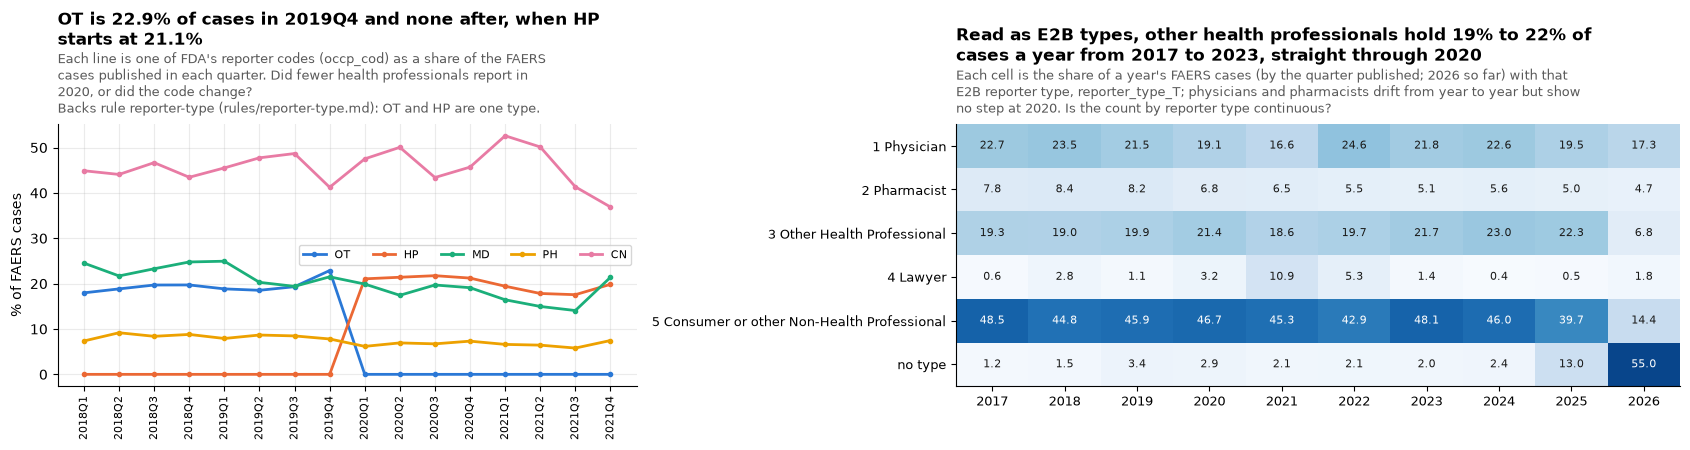

HP first above 1% of cases in 2020Q1; OT last above 1% in 2019Q4.
Physicians and pharmacists, share of cases a year: 1 Physician 16.6% to 24.6%; 2 Pharmacist 5.1% to 8.4% (2017 to 2023).
Coded cases with no E2B type: 11 (SALES 10, 20120210 1).


,cases,FDA's README,E2B(R3) type
code,,,
CN,8957853,Consumer,5 Consumer or other Non-Health Professional
MD,4395771,Physician,1 Physician
OT,1937675,Other health-professional,3 Other Health Professional
HP,1830178,not in the README,3 Other Health Professional
(empty),1381575,not in the README,none
PH,1257126,Pharmacist,2 Pharmacist
LW,528342,Lawyer,4 Lawyer
RN,8249,not in the README,3 Other Health Professional
SALES,10,not in the README,none


  checked twice: coded cases with no reporter type = 11


  checked twice: cases read as other health professional = 3,776,102


In [11]:
cl6 = code_list(6)
MAP = (
    pd.read_csv(rulebook.data_root() / rulebook.value("reporter-type", "mapping"), dtype=str)
    .set_index("fda_value")
    .e2b_code
)
rep = q(
    "SELECT quarter_T, coalesce(occp_cod, '(empty)') code, count(*) n FROM kept_T WHERE era_T = 'faers' GROUP BY ALL"
)
R5 = (
    rep.pivot_table(index="quarter_T", columns="code", values="n", aggfunc="sum")
    .reindex(FAERS_Q)
    .fillna(0)
)
R5 = 100 * R5.div(R5.sum(axis=1), axis=0)
first_hp = next(x for x in FAERS_Q if R5.loc[x, "HP"] >= 1)
last_ot = max(x for x in FAERS_Q if R5.loc[x, "OT"] >= 1)
ot_after = R5.loc[[x for x in FAERS_Q if x > last_ot], "OT"].max()
hp_year = int(first_hp[:4])
win = [x for x in FAERS_Q if f"{hp_year - 2}q1" <= x <= f"{hp_year + 1}q4"]
types = q("""SELECT left(quarter_T, 4)::INT yr, coalesce(reporter_type_T, 'none') t, count(*) n FROM kept_T
             WHERE era_T = 'faers' AND left(quarter_T, 4)::INT >= 2017 GROUP BY ALL""")
T5 = types.pivot_table(index="t", columns="yr", values="n", aggfunc="sum").fillna(0)
T5 = 100 * T5 / T5.sum()
T5 = T5.reindex(["1", "2", "3", "4", "5", "none"]).fillna(0)
T5.index = [f"{c} {cl6[c]}" if c in cl6 else "no type" for c in T5.index]
near = [y for y in T5.columns if hp_year - 3 <= y <= hp_year + 3]
oth = T5.iloc[2][near]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1, 1.25]})
for i, c in enumerate(["OT", "HP", "MD", "PH", "CN"]):
    a1.plot(range(len(win)), R5.loc[win, c], marker="o", ms=3, color=SERIES[i], label=c)
a1.set_xticks(range(len(win)))
a1.set_xticklabels([Q(x) for x in win], rotation=90, fontsize=8)
a1.set_ylabel("% of FAERS cases")
a1.legend(ncol=5, fontsize=8)
title(
    a1,
    f"OT is {R5.loc[last_ot, 'OT']:.1f}% of cases in {Q(last_ot)} and {'none' if ot_after == 0 else 'almost none'} after, when HP starts at {R5.loc[first_hp, 'HP']:.1f}%",
    "Each line is one of FDA's reporter codes (occp_cod) as a share of the FAERS cases published in each quarter.",
    "Did fewer health professionals report in 2020, or did the code change?",
    backs="Backs rule reporter-type (rules/reporter-type.md): OT and HP are one type.",
    width=78,
)
a2.imshow(T5.values, cmap="Blues", aspect="auto", vmin=0, vmax=60)
a2.grid(False)
a2.set_xticks(range(len(T5.columns)))
a2.set_xticklabels([str(y) for y in T5.columns], fontsize=9)
a2.set_yticks(range(len(T5)))
a2.set_yticklabels(T5.index, fontsize=9)
for (i, j), v in np.ndenumerate(T5.values):
    a2.text(
        j,
        i,
        f"{v:.1f}",
        ha="center",
        va="center",
        fontsize=8,
        color="white" if v >= 35 else "#1a1a19",
    )
title(
    a2,
    f"Read as E2B types, other health professionals hold {oth.min():.0f}% to {oth.max():.0f}% of cases a year from {near[0]} to {near[-1]}, straight through {hp_year}",
    f"Each cell is the share of a year's FAERS cases (by the quarter published; {T5.columns[-1]} so far) with that E2B reporter type, "
    f"reporter_type_T; physicians and pharmacists drift from year to year but show no step at {hp_year}.",
    "Is the count by reporter type continuous?",
    width=96,
)
plt.tight_layout()
plt.show()
tab = q(
    "SELECT coalesce(occp_cod, '(empty)') code, count(*) cases FROM kept_T GROUP BY 1 ORDER BY 2 DESC"
).set_index("code")
README = {
    "MD": "Physician",
    "PH": "Pharmacist",
    "OT": "Other health-professional",
    "LW": "Lawyer",
    "CN": "Consumer",
}
tab["FDA's README"] = tab.index.map(lambda c: README.get(c, "not in the README"))
tab["E2B(R3) type"] = tab.index.map(lambda c: f"{MAP[c]} {cl6[MAP[c]]}" if c in MAP else "none")
odd = tab[~tab.index.isin(list(MAP.index) + ["(empty)"])]
print(f"HP first above 1% of cases in {Q(first_hp)}; OT last above 1% in {Q(last_ot)}.")
print(
    "Physicians and pharmacists, share of cases a year: "
    + "; ".join(
        f"{T5.index[i]} {T5.iloc[i][near].min():.1f}% to {T5.iloc[i][near].max():.1f}%"
        for i in (0, 1)
    )
    + f" ({near[0]} to {near[-1]})."
)
print(
    f"Coded cases with no E2B type: {int(odd.cases.sum()):,} ("
    + ", ".join(f"{c} {n:,}" for c, n in odd.cases.items())
    + ")."
)
display(tab)
check(
    "coded cases with no reporter type",
    int(odd.cases.sum()),
    one(f"SELECT count(*) {kept_join} AND c.occp_cod IS NOT NULL AND c.reporter_type_T IS NULL"),
)
check(
    "cases read as other health professional",
    int(tab.cases[tab.index.isin(["OT", "HP", "RN"])].sum()),
    one(f"SELECT count(*) {kept_join} AND c.reporter_type_T = '3'"),
)

**What section 5 shows**, one item per chart:

- **FDA's codes around 2020.** *Shows:* OT is 22.9% of FAERS cases in 2019Q4 and none after; HP starts at 21.1% in 2020Q1; MD, PH and CN carry on. *Point:* HP is OT under a new name. *So what:* rule `reporter-type` reads OT, HP and RN as one type, other health professional; HP and RN are not in FDA's code list, so that reading is ours and the mapping says why.
- **E2B types by year.** *Shows:* other health professionals hold 19% to 22% of FAERS cases a year from 2017 to 2023, with no break at 2020; physicians drift between 17% and 25% and pharmacists between 5% and 8%, with no step at 2020 like OT's. Only 11 coded cases get no type: 10 SALES and 1 legacy case whose columns are shifted, its code a date. *Point:* counted by type, who reports is continuous across the change. *So what:* the explorer's reporter filter and chart count by `reporter_type_T`, with FDA's code beside it in the case window.

## 6. Report type: what 30DAY and 5DAY mean

`rept_cod` is FDA's regulatory category, not E2B's "type of report" (spontaneous, study, other), which FAERS does not publish. FDA's README calls EXP "expedited (15-day)", PER "periodic", DIR "direct", and 5DAY and 30DAY "combination product reports". FDA's E2B(R3) slides define its Local Criteria Report Type, FDA.C.1.7.1 (<https://www.fda.gov/media/135633/download>, page 21):

> 1=15-Day; 2=Periodic; 4=5-Day; 5=30-Day; 6=7-Day ... 5 for malfunction with no associated adverse event ... C.1.7 must be false if FDA.C.1.7.1 is 2 or 5

C.1.7 is E2B's "does this case fulfil the local criteria for an expedited report?". So a 30-day report is not expedited. Both types come from FDA's postmarketing safety reporting rule for combination products (21 CFR Part 4, subpart B, in force from 31 July 2020): a 5-day report where remedial action is needed to prevent a risk to public health, a 30-day report for a malfunction of the device part. DiAna turns both into EXP in one line, and gives no reason (`Cleaning_script.R`, line 455):

```r
Demo[rept_cod %in% c("30DAY", "5DAY")]$rept_cod <- "EXP"
```

Its package labels all three "Expedited". Open Altio keeps FDA's report type as given, and the explorer shows it in FDA's own words.

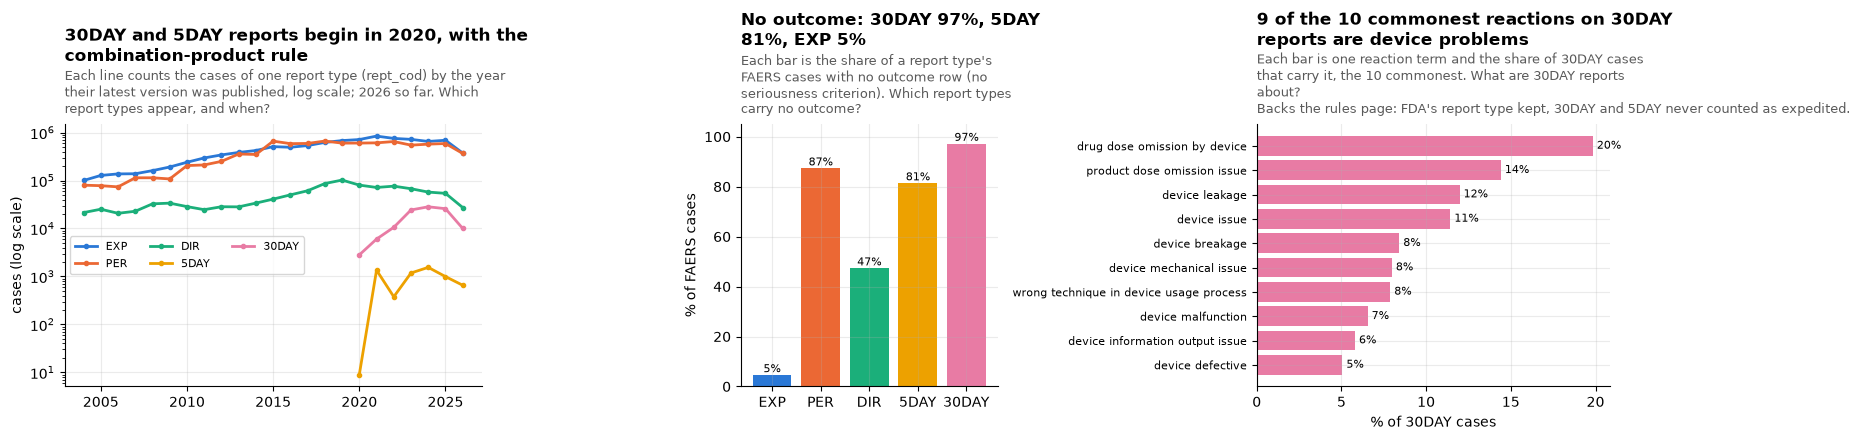

30DAY: 107,884 cases since 2020, 97.3% with no outcome. 5DAY: 6,112 cases, 81.4% with no outcome.
Expedited (EXP) cases with no outcome: 397,343 in FAERS, 435,405 in both eras (section 8).


,FDA.C.1.7.1,expedited (FDA C.1.7),DiAna,cases
EXP,1 15-Day,yes,EXP,10124972
PER,2 Periodic,no,PER,8982680
DIR,"none (sent on MedWatch, not E2B)",not applicable,DIR,1075124
5DAY,4 5-Day,yes,EXP,6112
30DAY,5 30-Day,no,EXP,107884


  checked twice: 30DAY cases = 107,884


  checked twice: 5DAY cases = 6,112


  checked twice: FAERS expedited cases with no outcome = 397,343


In [12]:
RTYPE = pd.DataFrame(
    {
        "FDA.C.1.7.1": [
            "1 15-Day",
            "2 Periodic",
            "none (sent on MedWatch, not E2B)",
            "4 5-Day",
            "5 30-Day",
        ],
        "expedited (FDA C.1.7)": ["yes", "no", "not applicable", "yes", "no"],
        "DiAna": ["EXP", "PER", "DIR", "EXP", "EXP"],
    },
    index=["EXP", "PER", "DIR", "5DAY", "30DAY"],
)
per_year = q(
    "SELECT left(quarter_T, 4)::INT yr, coalesce(rept_cod, '(empty)') rept_cod, count(*) n FROM kept_T GROUP BY ALL"
).pivot(index="yr", columns="rept_cod", values="n")
no_out = (
    q("""SELECT k.rept_cod, count(*) n, count(*) FILTER (WHERE o.primaryid IS NULL) n_none, 100 * avg((o.primaryid IS NULL)::INT) pct FROM kept_T k
              LEFT JOIN (SELECT DISTINCT era_T, primaryid, quarter_T FROM outc_k_T) o USING (era_T, primaryid, quarter_T)
              WHERE k.era_T = 'faers' AND k.rept_cod IS NOT NULL GROUP BY 1""")
    .set_index("rept_cod")
    .reindex(RTYPE.index)
)
top30 = q("""SELECT lower(r.pt) pt, count(DISTINCT k.primaryid) n FROM kept_T k JOIN reac_latest_T r USING (era_T, primaryid, quarter_T)
             WHERE k.rept_cod = '30DAY' GROUP BY 1 ORDER BY 2 DESC LIMIT 10""")
first30 = int(per_year["30DAY"].first_valid_index())
fig, (a1, a2, a3) = plt.subplots(
    1, 3, figsize=(18, 4.5), gridspec_kw={"width_ratios": [1.3, 0.8, 1.1]}
)
for i, c in enumerate(RTYPE.index):
    if c in per_year:
        s = per_year[c].dropna()
        a1.plot(s.index, s.values, marker="o", ms=3, color=SERIES[i], label=c)
a1.set_yscale("log")
a1.set_ylabel("cases (log scale)")
a1.legend(fontsize=8, ncol=3, loc="center left")
title(
    a1,
    f"30DAY and 5DAY reports begin in {first30}, with the combination-product rule",
    f"Each line counts the cases of one report type (rept_cod) by the year their latest version was published, log scale; {per_year.index[-1]} so far.",
    "Which report types appear, and when?",
    width=70,
)
label_bars(a2, a2.bar(no_out.index, no_out.pct, color=[SERIES[i] for i in range(5)]), "{:.0f}%")
a2.set_ylim(0, 105)
a2.set_ylabel("% of FAERS cases")
title(
    a2,
    f"No outcome: 30DAY {no_out.pct['30DAY']:.0f}%, 5DAY {no_out.pct['5DAY']:.0f}%, EXP {no_out.pct['EXP']:.0f}%",
    "Each bar is the share of a report type's FAERS cases with no outcome row (no seriousness criterion).",
    "Which report types carry no outcome?",
    width=44,
)
n30 = int(per_year["30DAY"].sum())
label_bars(
    a3,
    a3.barh(top30.pt[::-1], 100 * top30.n[::-1] / n30, color=SERIES[4]),
    "{:.0f}%",
    horizontal=True,
)
a3.set_xlabel("% of 30DAY cases")
a3.tick_params(axis="y", labelsize=8)
title(
    a3,
    f"{int(top30.pt.str.contains('device').sum())} of the 10 commonest reactions on 30DAY reports are device problems",
    "Each bar is one reaction term and the share of 30DAY cases that carry it, the 10 commonest.",
    "What are 30DAY reports about?",
    backs="Backs the rules page: FDA's report type kept, 30DAY and 5DAY never counted as expedited.",
    width=59,
)
plt.tight_layout()
plt.show()
n5 = int(per_year["5DAY"].sum())
exp_none_faers = int(no_out.n_none["EXP"])
exp_none_all = one("""SELECT count(*) FROM kept_T k WHERE k.rept_cod = 'EXP'
                      AND NOT EXISTS (SELECT 1 FROM outc_k_T o WHERE o.era_T = k.era_T AND o.primaryid = k.primaryid AND o.quarter_T = k.quarter_T)""")
print(
    f"30DAY: {n30:,} cases since {first30}, {no_out.pct['30DAY']:.1f}% with no outcome. 5DAY: {n5:,} cases, {no_out.pct['5DAY']:.1f}% with no outcome."
)
print(
    f"Expedited (EXP) cases with no outcome: {exp_none_faers:,} in FAERS, {exp_none_all:,} in both eras (section 8)."
)
display(RTYPE.assign(cases=[int(per_year[c].sum()) for c in RTYPE.index]))
check("30DAY cases", n30, one(f"SELECT count(*) {kept_join} AND c.rept_cod = '30DAY'"))
check("5DAY cases", n5, one(f"SELECT count(*) {kept_join} AND c.rept_cod = '5DAY'"))
check(
    "FAERS expedited cases with no outcome",
    exp_none_faers,
    one(f"""SELECT count(*) {kept_join} AND c.era_T = 'faers' AND c.rept_cod = 'EXP' AND (c.era_T, c.primaryid, c.quarter_T) NOT IN
          (SELECT (era_T, primaryid, quarter_T) FROM outc_latest_T)"""),
)

**What section 6 shows**, one item per chart:

- **Report types by year.** *Shows:* 30DAY (107,884 cases) and 5DAY (6,112) begin in 2020. *Point:* they arrive with FDA's combination-product rule. *So what:* nothing to clean; they are named as FDA names them.
- **No outcome by report type.** *Shows:* in FAERS cases, 30DAY has no outcome on 97%, 5DAY on 81%, EXP on 4.7% (397,343 cases; 435,405 counting legacy AERS too). *Point:* a 30-day report is a device malfunction with no adverse event, as FDA's rule says. *So what:* calling it expedited, as DiAna does, contradicts FDA's own E2B(R3) rule; we keep FDA's report type and never regroup it.
- **What 30DAY reports are about.** *Shows:* 9 of the 10 commonest reactions on 30DAY reports are device problems. *Point:* these reports are about the pen, injector or pump, not a reaction. *So what:* a search by report type finds them as FDA wrote them; an "expedited" count leaves them out.

## 7. Frequency, repeated drug numbers and dose form

Routes are read by the route step (`drug-route`), with its own evidence, and are not counted here.

**Frequency.** `dose_freq` is FDA's short code (QD, BID, ...), defined in FDA's README; the explorer shows FDA's own words for it ("Twice a day"). E2B(R3) has no frequency code: it sends the interval between doses as a number and a unit (G.k.4.r.2 and r.3, ICH code list 26). Turning "twice a day" into "every 12 hours" would state a spacing no reporter gave, so the release keeps FDA's code and the explorer FDA's words. DiAna keeps FDA's codes too.

**Repeated drug numbers.** A drug record is a case and its drug sequence number (`drug_seq`). From 2024Q4 FDA often writes one drug on several rows, one per dosage regimen (a loading and a maintenance dose, say), all under the same `drug_seq`. The right chart follows the share of drug rows that share their number.

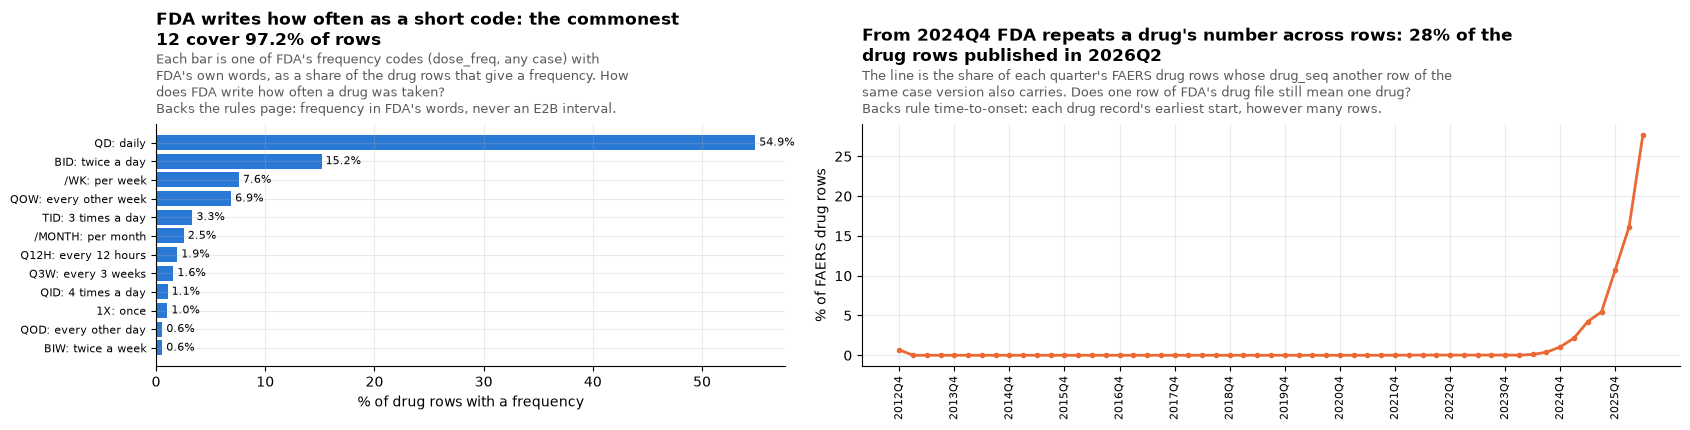

Drug rows with a frequency: 15,831,546; FDA's codes and words cover them as written. DiAna's frequency table keeps FDA's code for 86.2% of the rows it counts.
Drug rows sharing their drug_seq: 1,037,144; under 0.7% a quarter before 2024Q4, 27.7% in 2026Q2. A count of drugs must count a case's distinct drug_seq, not rows.


  checked twice: drug rows with a frequency = 15,831,546


  checked twice: FAERS drug rows sharing their drug_seq = 1,037,144


In [13]:
FREQ_WORDS = {
    "QD": "daily",
    "BID": "twice a day",
    "TID": "3 times a day",
    "QID": "4 times a day",
    "QW": "weekly",
    "QOW": "every other week",
    "QM": "monthly",
    "PRN": "as needed",
    "1X": "once",
    "QOD": "every other day",
    "HS": "at bedtime",
    "Q3W": "every 3 weeks",
    "BIW": "twice a week",
    "TIW": "3 times a week",
    "Q12H": "every 12 hours",
    "Q8H": "every 8 hours",
    "Q6H": "every 6 hours",
    "Q4H": "every 4 hours",
    "UNK": "unknown",
    "/DAY": "per day",
    "/WK": "per week",
    "/MONTH": "per month",
    "/CYCLE": "per cycle",
}  # FDA's README, in the explorer's words
fr = q(
    "SELECT upper(dose_freq) f, count(*) n FROM drug_k_T WHERE dose_freq IS NOT NULL GROUP BY 1 ORDER BY 2 DESC"
)
top = fr.head(12)
dq = pd.read_csv(
    DIANA / "dose_freq_st.csv", sep=";", dtype=str, keep_default_na=False, na_values=["NA"]
).dropna(subset=["dose_freq", "dose_freq_st"])
dq["N"] = dq.N.astype(float)
diana_keeps = 100 * dq.N[dq.dose_freq.str.upper() == dq.dose_freq_st.str.upper()].sum() / dq.N.sum()
rep = (
    q("""SELECT quarter_T, sum(c) FILTER (WHERE c > 1) repeated, sum(c) all_rows FROM (SELECT quarter_T, primaryid, drug_seq, count(*) c FROM drug_k_T
           WHERE era_T = 'faers' GROUP BY ALL) GROUP BY 1""")
    .set_index("quarter_T")
    .reindex(FAERS_Q)
    .fillna(0)
)
rep["pct"] = 100 * rep.repeated / rep.all_rows
first_rep = rep[rep.pct >= 1].index.min()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(17, 4.4), gridspec_kw={"width_ratios": [1, 1.3]})
label_bars(
    a1,
    a1.barh(
        [f"{c}: {FREQ_WORDS.get(c, '')}" for c in top.f[::-1]],
        100 * top.n[::-1] / fr.n.sum(),
        color=SERIES[0],
    ),
    "{:.1f}%",
    horizontal=True,
)
a1.set_xlabel("% of drug rows with a frequency")
a1.tick_params(axis="y", labelsize=8)
title(
    a1,
    f"FDA writes how often as a short code: the commonest {len(top)} cover {100 * top.n.sum() / fr.n.sum():.1f}% of rows",
    "Each bar is one of FDA's frequency codes (dose_freq, any case) with FDA's own words, as a share of the drug rows that give a frequency.",
    "How does FDA write how often a drug was taken?",
    backs="Backs the rules page: frequency in FDA's words, never an E2B interval.",
    width=72,
)
a2.plot(range(len(rep)), rep.pct, color=SERIES[1], marker="o", ms=3)
a2.set_xticks(range(0, len(rep), 4))
a2.set_xticklabels([Q(x) for x in rep.index[::4]], rotation=90, fontsize=8)
a2.set_ylabel("% of FAERS drug rows")
title(
    a2,
    f"From {Q(first_rep)} FDA repeats a drug's number across rows: {rep.pct.iloc[-1]:.0f}% of the drug rows published in {Q(rep.index[-1])}",
    "The line is the share of each quarter's FAERS drug rows whose drug_seq another row of the same case version also carries.",
    "Does one row of FDA's drug file still mean one drug?",
    backs="Backs rule time-to-onset: each drug record's earliest start, however many rows.",
    width=90,
)
plt.tight_layout()
plt.show()
print(
    f"Drug rows with a frequency: {int(fr.n.sum()):,}; FDA's codes and words cover them as written. DiAna's frequency table keeps FDA's code for {diana_keeps:.1f}% of the rows it counts."
)
print(
    f"Drug rows sharing their drug_seq: {int(rep.repeated.sum()):,}; under {rep.pct[rep.index < first_rep].max():.1f}% a quarter before {Q(first_rep)}, {rep.pct.iloc[-1]:.1f}% in {Q(rep.index[-1])}. "
    "A count of drugs must count a case's distinct drug_seq, not rows."
)
check(
    "drug rows with a frequency",
    int(fr.n.sum()),
    one(
        "SELECT count(dose_freq) FROM drug_latest_T WHERE (era_T, primaryid, quarter_T) IN (SELECT (era_T, primaryid, quarter_T) FROM kept_T)"
    ),
)
check(
    "FAERS drug rows sharing their drug_seq",
    int(rep.repeated.sum()),
    one(
        """SELECT count(*) FROM (SELECT count(*) OVER (PARTITION BY quarter_T, primaryid, drug_seq) c FROM drug_k_T WHERE era_T = 'faers') WHERE c > 1"""
    ),
)

### Does DiAna's dose form say what FDA's words say?

FDA's `dose_form` is free text. E2B(R3) wants an EDQM Standard Term, which needs EDQM's licence; DiAna's table maps FAERS spellings to its own 163 forms (CC BY 4.0). To test it, the 176 spellings that cover 99% of the dose form rows were each read twice, apart, against DiAna's forms only: the form or forms the words support, several where the words allow several, never broader or narrower than the words. Neither reading saw DiAna's answer or the other reading. Each spelling falls in one category:

1. DiAna agrees with both readings.
2. DiAna picks one of several forms the words allow ("injection" could be a solution, a suspension, an emulsion or a powder).
3. DiAna differs from both readings, which agree.
4. The readings differ, and DiAna agrees with one.
5. The readings differ, and DiAna agrees with neither.

The left chart weighs each category by this release's drug rows; the right names the largest differences.

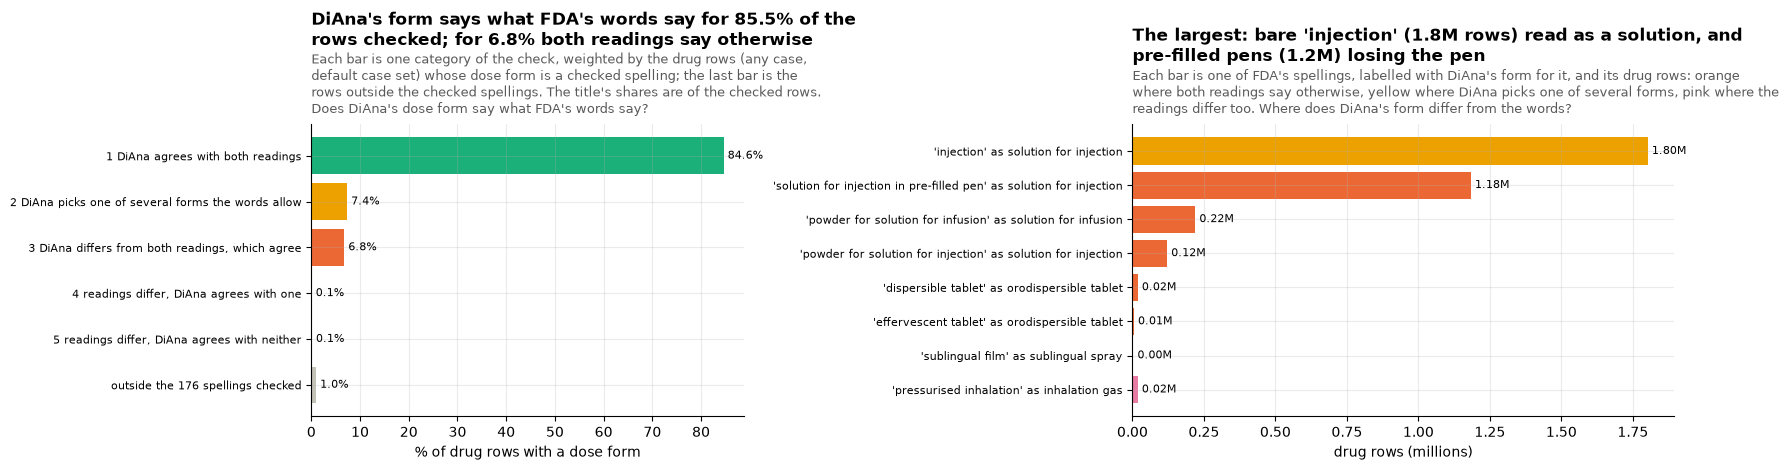

Categories, share of the checked rows: 1 85.5%; 2 7.4%; 3 6.8%; 4 0.1%; 5 0.1%. Rows outside the checked spellings: 1.0%.
  'injection' (1,802,627 rows): DiAna solution for injection; readings: emulsion for injection; powder for injection; solution for injection; suspension for injection | emulsion for injection; powder for injection; solution for injection; suspension for injection
  'solution for injection in pre-filled pen' (1,183,942 rows): DiAna solution for injection; readings: pen | pen
  'powder for solution for infusion' (220,091 rows): DiAna solution for infusion; readings: powder for infusion | powder for infusion
  'powder for solution for injection' (121,657 rows): DiAna solution for injection; readings: powder for injection | powder for injection
  'dispersible tablet' (19,058 rows): DiAna orodispersible tablet; readings: tablet | tablet
  'effervescent tablet' (5,535 rows): DiAna orodispersible tablet; readings: tablet | tablet
  'sublingual film' (3,615 rows): DiAna sub

  checked twice: drug rows with a dose form = 29,361,686


In [14]:
CATS = {
    "1": "1 DiAna agrees with both readings",
    "2": "2 DiAna picks one of several forms the words allow",
    "3": "3 DiAna differs from both readings, which agree",
    "4": "4 readings differ, DiAna agrees with one",
    "5": "5 readings differ, DiAna agrees with neither",
}
OUTSIDE = "outside the 176 spellings checked"
cmp_ = pd.read_csv(DOSE_FORM_CHECK / "compare.csv", dtype=str, keep_default_na=False)
cmp_["cat"] = cmp_.category.str[0].map(CATS)
dfm = pd.read_csv(
    DIANA / "dose_form_st.csv", sep=";", dtype=str, keep_default_na=False, na_values=["NA"]
).dropna(subset=["dose_form"])
dfm["key"] = dfm.dose_form.str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
diana_now = dfm.groupby("key").dose_form_st.agg(
    lambda s: ";".join(sorted(set(s.dropna()))) or "none"
)
same = (cmp_.spelling.map(diana_now).fillna("missing") == cmp_.diana.str.replace("; ", ";")).sum()
assert same == len(cmp_), (
    f"DiAna's answer in the check differs from its table for {len(cmp_) - same} spellings"
)
forms = q("""SELECT lower(trim(regexp_replace(dose_form, '[[:space:]]+', ' ', 'g'))) spelling, count(*) n FROM drug_k_T
             WHERE dose_form IS NOT NULL GROUP BY 1""").merge(cmp_, on="spelling", how="left")
forms["cat"] = forms.cat.fillna(OUTSIDE)
by_cat = forms.groupby("cat").n.sum().reindex(list(CATS.values()) + [OUTSIDE]).fillna(0)
share = 100 * by_cat / by_cat.sum()
checked_share = 100 * by_cat.drop(OUTSIDE) / by_cat.drop(OUTSIDE).sum()
EXAMPLES = [
    "injection",
    "solution for injection in pre-filled pen",
    "powder for solution for infusion",
    "powder for solution for injection",
    "dispersible tablet",
    "effervescent tablet",
    "sublingual film",
    "pressurised inhalation",
]
ex = forms.set_index("spelling").loc[EXAMPLES]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1, 1.25]})
label_bars(
    a1,
    a1.barh(
        share.index,
        share.values,
        color=[SERIES[2], SERIES[3], SERIES[1], SERIES[6], SERIES[4], SERIES[7]],
    ),
    "{:.1f}%",
    horizontal=True,
)
a1.invert_yaxis()
a1.set_xlabel("% of drug rows with a dose form")
a1.tick_params(axis="y", labelsize=8)
title(
    a1,
    f"DiAna's form says what FDA's words say for {checked_share[CATS['1']]:.1f}% of the rows checked; for {checked_share[CATS['3']]:.1f}% both readings say otherwise",
    "Each bar is one category of the check, weighted by the drug rows (any case, default case set) whose dose form is a checked spelling; "
    "the last bar is the rows outside the checked spellings. The title's shares are of the checked rows.",
    "Does DiAna's dose form say what FDA's words say?",
    width=80,
)
labels = [f"'{s}' as {r.diana}" for s, r in ex.iterrows()]
label_bars(
    a2,
    a2.barh(
        labels[::-1],
        ex.n[::-1] / 1e6,
        color=[
            SERIES[1] if c.startswith("3") else SERIES[3] if c.startswith("2") else SERIES[4]
            for c in ex.cat[::-1]
        ],
    ),
    "{:.2f}M",
    horizontal=True,
)
a2.set_xlabel("drug rows (millions)")
a2.tick_params(axis="y", labelsize=8)
title(
    a2,
    f"The largest: bare 'injection' ({ex.n['injection'] / 1e6:.1f}M rows) read as a solution, and pre-filled pens ({ex.n['solution for injection in pre-filled pen'] / 1e6:.1f}M) losing the pen",
    "Each bar is one of FDA's spellings, labelled with DiAna's form for it, and its drug rows: orange where both readings say otherwise, "
    "yellow where DiAna picks one of several forms, pink where the readings differ too.",
    "Where does DiAna's form differ from the words?",
    width=96,
)
plt.tight_layout()
plt.show()
print(
    "Categories, share of the checked rows: "
    + "; ".join(f"{k[0]} {v:.1f}%" for k, v in checked_share.items())
    + f". Rows outside the checked spellings: {share[OUTSIDE]:.1f}%."
)
for s, r in ex.iterrows():
    print(f"  '{s}' ({r.n:,} rows): DiAna {r.diana}; readings: {r.run_a} | {r.run_b}")
print(
    f"DiAna's answer in the check is the answer in its table today for all {len(cmp_)} spellings."
)
check(
    "drug rows with a dose form",
    int(by_cat.sum()),
    one("SELECT count(dose_form) FROM drug_dedup_T"),
)

**What section 7 shows**, one item per chart:

- **Frequency codes.** *Shows:* in drug rows with a frequency (15,831,340), the commonest 12 of FDA's codes cover 97.2%; DiAna's own table keeps FDA's code for 86.2% of the rows it counts. *Point:* frequency is already a short code list with plain words. *So what:* the release keeps FDA's code and the explorer shows FDA's words; no E2B interval is made up.
- **Repeated drug numbers.** *Shows:* from 2024Q4, FDA writes one drug on several rows under one `drug_seq`: 28% of the FAERS drug rows published in 2026Q2, 1,037,144 rows in all. *Point:* a row of FDA's drug file is no longer a drug. *So what:* a count of drugs counts a case's distinct `drug_seq`; time to onset takes each drug record's earliest start, however many rows it has.
- **The dose form check, by category.** *Shows:* weighted by this release's drug rows, DiAna agrees with both readings for 85.5% of the checked rows, picks one of several allowed forms for 7.4%, and differs from two agreeing readings for 6.8%; the readings themselves differ on 0.2%. *Point:* DiAna is right for most rows, but for about one row in seven it says more than the words, or something else. *So what:* the open item below.
- **The largest differences.** *Shows:* bare "injection" (1.8 million rows) read as a solution; "solution for injection in pre-filled pen" (1.2 million) losing the pen; powders for solution read as the solution; dispersible and effervescent tablets as orodispersible; sublingual film as a sublingual spray; pressurised inhalation as an inhalation gas. *Point:* each is a reading the words do not support. *So what:* a dose form table we publish must be reviewed spelling by spelling.

## 8. Outcomes: their order, and cases with none

`outc_cod` lists the seriousness criteria of the latest version, one row per criterion: death (DE), life-threatening (LT), hospitalisation (HO), disability (DS), congenital anomaly (CA), required intervention (RI) and other serious (OT). E2B(R3) sends these as yes/no flags per reaction with no order (E.i.3.2a to f); RI is FDA's own (FDA.E.i.3.2h, a device and medication-error outcome). If a reaction is not serious "or there is no information regarding seriousness", E2B sends nothing. DiAna orders them OT < CA < HO < RI < DS < LT < DE, takes the most severe per case, and calls a case with none "Non Serious". FDA's README lists them DE, LT, HO, DS, CA, RI, OT.

The release keeps the set of criteria; where one most-severe outcome is needed, it uses FDA's README order. A case with no outcome is never called non-serious: periodic reports are mostly about non-serious reactions, but an expedited report is sent within 15 days because the reaction is serious, so an expedited case with no outcome is shown as "sent as an expedited report, which is for serious reactions, but FDA gives no seriousness criterion". No count changes.

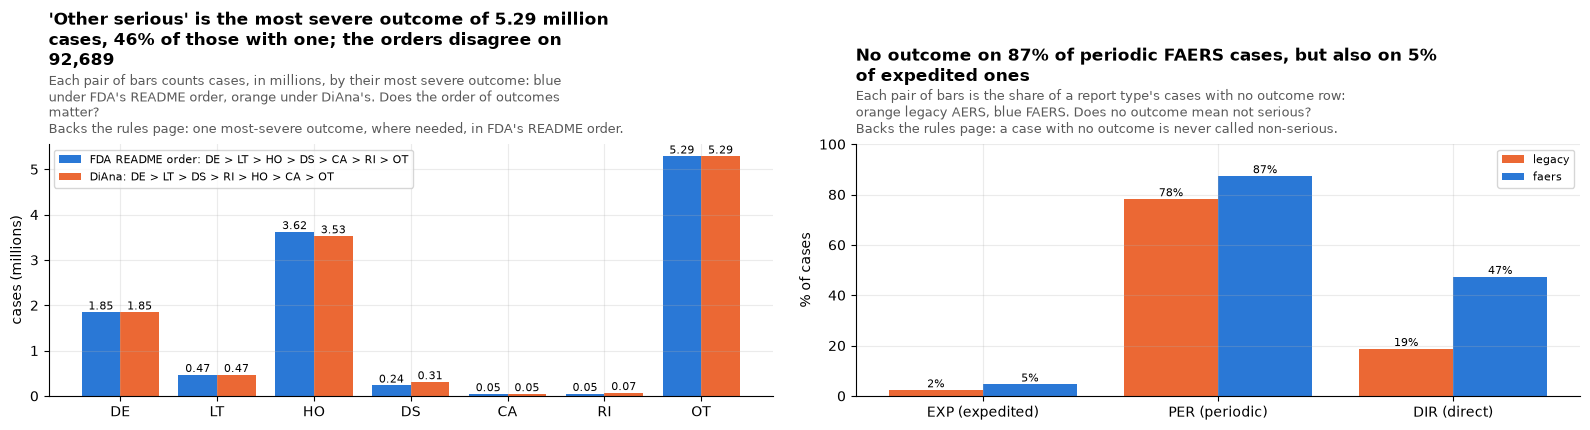

Cases with at least one outcome: 11,561,436 (57.0%); with none: 8,735,344. The two orders pick a different most severe outcome for 92,689 cases (0.8%). Expedited (EXP) cases with no outcome: 435,405, both eras (397,343 FAERS).


how,DiAna order,FDA README order,"FDA order, % of cases with an outcome"
code,,,
DE,1848032,1848032,16.0
LT,469458,469458,4.1
HO,3528613,3621129,31.3
DS,309355,235731,2.0
CA,45821,45994,0.4
RI,70516,51451,0.4
OT,5289641,5289641,45.8


  checked twice: cases with at least one outcome = 11,561,436


  checked twice: cases where the two orders differ = 92,689
  checked twice: expedited cases with no outcome, both eras = 435,405


In [15]:
DIANA_ORDER = ["DE", "LT", "DS", "RI", "HO", "CA", "OT"]
FDA_ORDER = ["DE", "LT", "HO", "DS", "CA", "RI", "OT"]


def rank(order):
    return (
        "CASE outc_cod "
        + " ".join(f"WHEN '{c}' THEN {len(order) - i}" for i, c in enumerate(order))
        + " END"
    )


con.execute(f"""CREATE OR REPLACE TEMP TABLE worst_T AS
SELECT era_T, primaryid, quarter_T, arg_max(outc_cod, {rank(FDA_ORDER)}) fda_T, arg_max(outc_cod, {rank(DIANA_ORDER)}) diana_T, count(*) n_codes
FROM outc_k_T GROUP BY ALL""")
W = (
    q(
        "SELECT 'FDA README order' how, fda_T code, count(*) n FROM worst_T GROUP BY ALL UNION ALL SELECT 'DiAna order', diana_T, count(*) FROM worst_T GROUP BY ALL"
    )
    .pivot(index="code", columns="how", values="n")
    .reindex(FDA_ORDER)
)
diff = q(
    'SELECT diana_T AS "DiAna\'s most severe", fda_T AS "FDA order\'s most severe", count(*) cases FROM worst_T WHERE diana_T <> fda_T GROUP BY ALL ORDER BY 3 DESC'
)
none = q("""SELECT k.era_T, k.rept_cod, count(*) n, count(*) FILTER (WHERE w.primaryid IS NULL) n_none FROM kept_T k LEFT JOIN worst_T w USING (era_T, primaryid, quarter_T)
            WHERE k.rept_cod IN ('EXP', 'PER', 'DIR') GROUP BY ALL""")
none["pct"] = 100 * none.n_none / none.n
with_out = one("SELECT count(*) FROM worst_T")
n_diff = int(diff.cases.sum())
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 4.4))
x = np.arange(len(W))
w = 0.4
label_bars(
    a1,
    a1.bar(
        x - w / 2,
        W["FDA README order"] / 1e6,
        w,
        color=SERIES[0],
        label="FDA README order: DE > LT > HO > DS > CA > RI > OT",
    ),
    "{:.2f}",
)
label_bars(
    a1,
    a1.bar(
        x + w / 2,
        W["DiAna order"] / 1e6,
        w,
        color=SERIES[1],
        label="DiAna: DE > LT > DS > RI > HO > CA > OT",
    ),
    "{:.2f}",
)
a1.set_xticks(x)
a1.set_xticklabels(W.index)
a1.set_ylabel("cases (millions)")
a1.legend(fontsize=8)
ot_worst = W.loc["OT", "FDA README order"]
title(
    a1,
    f"'Other serious' is the most severe outcome of {ot_worst / 1e6:.2f} million cases, {100 * ot_worst / with_out:.0f}% of those with one; the orders disagree on {n_diff:,}",
    "Each pair of bars counts cases, in millions, by their most severe outcome: blue under FDA's README order, orange under DiAna's.",
    "Does the order of outcomes matter?",
    backs="Backs the rules page: one most-severe outcome, where needed, in FDA's README order.",
    width=81,
)
P8 = none.pivot(index="rept_cod", columns="era_T", values="pct").reindex(["EXP", "PER", "DIR"])
for i, era in enumerate(["legacy", "faers"]):
    label_bars(
        a2, a2.bar(np.arange(3) + (i - 0.5) * w, P8[era], w, color=ERA[era], label=era), "{:.0f}%"
    )
a2.set_xticks(range(3))
a2.set_xticklabels(["EXP (expedited)", "PER (periodic)", "DIR (direct)"])
a2.set_ylim(0, 100)
a2.set_ylabel("% of cases")
a2.legend(fontsize=8)
title(
    a2,
    f"No outcome on {P8.loc['PER', 'faers']:.0f}% of periodic FAERS cases, but also on {P8.loc['EXP', 'faers']:.0f}% of expedited ones",
    "Each pair of bars is the share of a report type's cases with no outcome row: orange legacy AERS, blue FAERS.",
    "Does no outcome mean not serious?",
    backs="Backs the rules page: a case with no outcome is never called non-serious.",
    width=81,
)
plt.tight_layout()
plt.show()
exp_none = int(none[none.rept_cod == "EXP"].n_none.sum())
print(
    f"Cases with at least one outcome: {with_out:,} ({100 * with_out / N_CASES:.1f}%); with none: {N_CASES - with_out:,}. "
    f"The two orders pick a different most severe outcome for {n_diff:,} cases ({100 * n_diff / with_out:.1f}%). "
    f"Expedited (EXP) cases with no outcome: {exp_none:,}, both eras ({int(none[(none.rept_cod == 'EXP') & (none.era_T == 'faers')].n_none.sum()):,} FAERS)."
)
display(
    W.assign(
        **{
            "FDA order, % of cases with an outcome": (100 * W["FDA README order"] / with_out).round(
                1
            )
        }
    )
)
check(
    "cases with at least one outcome",
    with_out,
    one(
        f"SELECT count(*) {kept_join} AND EXISTS (SELECT 1 FROM outc_latest_T o WHERE o.era_T = c.era_T AND o.primaryid = c.primaryid AND o.quarter_T = c.quarter_T)"
    ),
)
check(
    "cases where the two orders differ",
    n_diff,
    one("""SELECT count(*) FROM (SELECT era_T, primaryid, quarter_T, list(outc_cod) l FROM outc_k_T GROUP BY ALL)
      WHERE NOT list_contains(l, 'DE') AND NOT list_contains(l, 'LT') AND ((list_contains(l, 'DS') OR list_contains(l, 'RI')) AND list_contains(l, 'HO')
            OR list_contains(l, 'RI') AND list_contains(l, 'CA') AND NOT list_contains(l, 'HO') AND NOT list_contains(l, 'DS'))"""),
)
check("expedited cases with no outcome, both eras", exp_none, exp_none_all)
_ = con.execute("DROP TABLE worst_T")

**What section 8 shows**, one item per chart:

- **Most severe outcome under each order.** *Shows:* of 11,561,325 cases with an outcome, 5.29 million have "other serious" as their most severe, 46% of them; the two orders disagree on 92,684 cases (0.8%), nearly all disability or required intervention against hospitalisation. *Point:* the order matters little; what "other serious" hides matters more. *So what:* where one most-severe outcome is needed, FDA's README order; the set of criteria is kept.
- **No outcome by report type.** *Shows:* no outcome on 87% of periodic FAERS cases and 4.7% of expedited ones: 435,405 expedited cases in both eras. *Point:* for periodic reports, mostly about non-serious reactions, no outcome fits; for expedited reports, serious by definition, it does not. *So what:* a case with no outcome is never called non-serious, and an expedited one says it was sent for serious reactions with no criterion given.

## 9. Dechallenge and rechallenge

**Dechallenge** asks: when the drug was stopped or its dose lowered, did the reaction go away? **Rechallenge** asks: when the drug was given again, did the reaction come back? FAERS answers each per drug, in `dechal` and `rechal`: Y (yes), N (no), U (unknown) or D (does not apply: the drug was not stopped, or not given again). A reaction that went away when the drug stopped and came back when it restarted is strong evidence the drug caused it.

Notebook 00 found `rechal` filled for almost every drug in FAERS files from 2012Q4 to 2015Q3, mostly with D, while `dechal` is almost empty, and asked whether the two were swapped. The quarter charts show each answer's share of drug rows, and the table sums them by period. The swap test uses drugs that came back in a later version: a drug row published in that window and the same drug (same case, drug sequence number and name) in the first later version published from 2016Q3. If the columns were swapped, the window's `rechal` would match the later `dechal`. It reads FDA's files for every version, so it is not limited to the default case set; counted in drug rows.

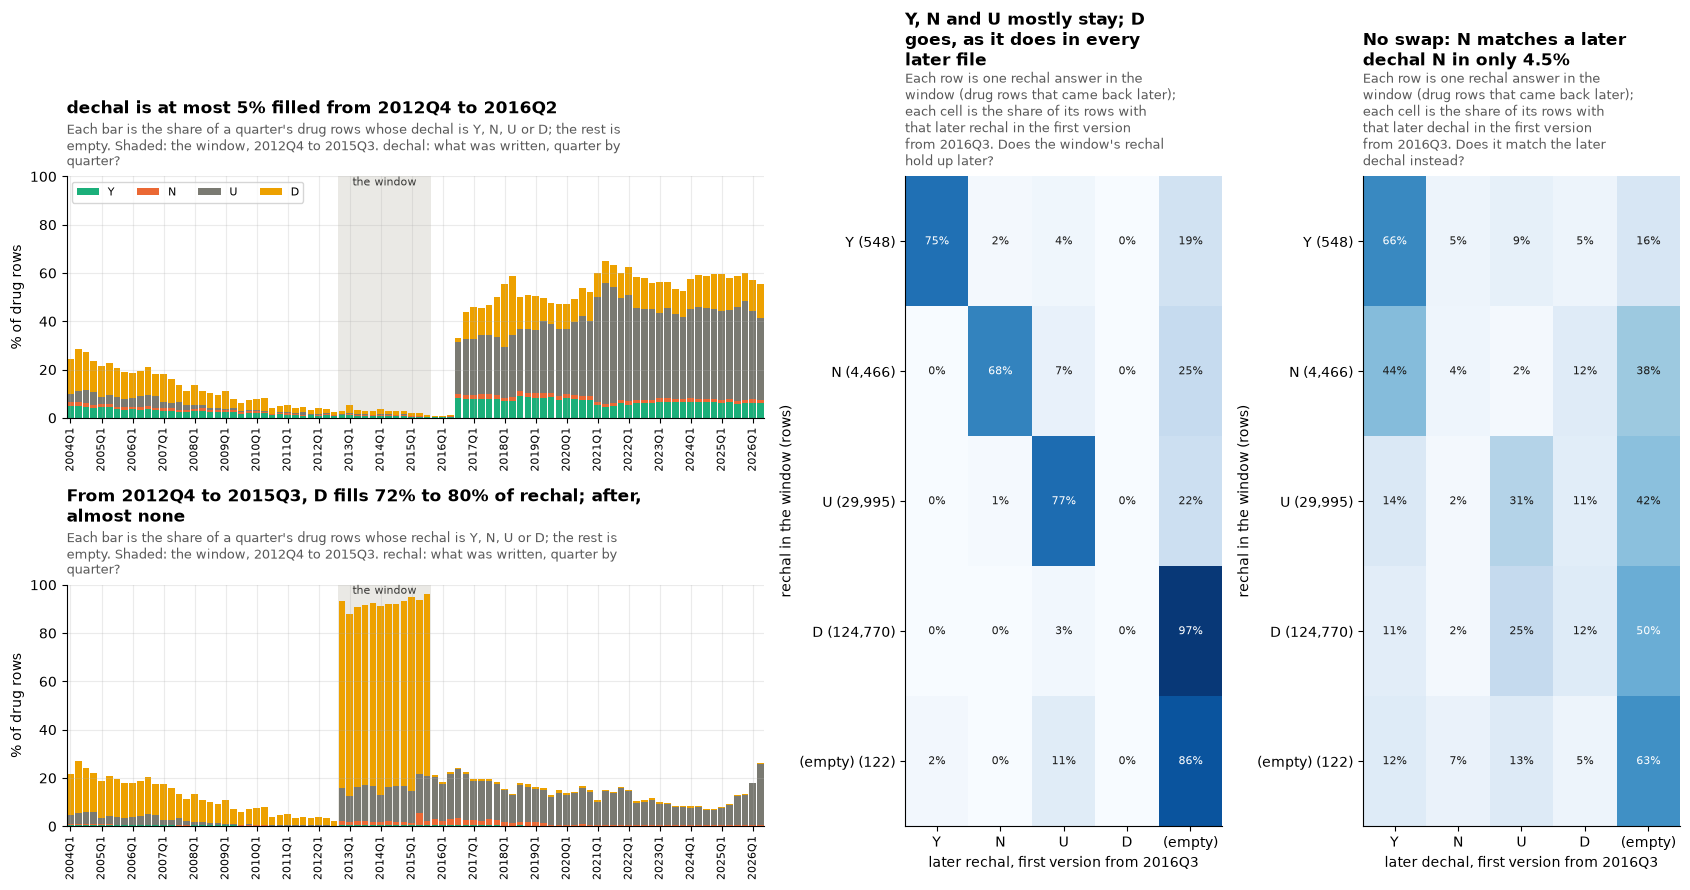

Drug rows published in the window (default case set): 8,729,212. rechal filled: 8,101,594 (93%), D: 6,642,927. dechal filled: 240,311 (2.8%).
Drug rows that came back from 2016Q3: 159,901; with a window D, 124,770, 1.9% of the window's 6,642,927 D rows.
Groups: Y 548, N 4,466, U 29,995. Y stays Y in 75%, N stays N in 68%, U stays U in 77%; a window D has no rechal later in 97%.
Against the later dechal: a window D is a later dechal D in 12.2%, a window N a later dechal N in 4.5%.
In files from 2016Q3, D is 0.61% of rechal rows: later files leave it blank instead. U is 83% to 96% of filled rechal a year from 2016, and 62% of filled dechal.


col                           dechal                          rechal                         
v                                  Y    N     U     D (empty)      Y    N     U     D (empty)
legacy AERS, 2004Q1 to 2012Q3    2.3  0.7   1.6   6.0    89.5    0.3  0.2   1.3   8.2    90.0
the window, 2012Q4 to 2015Q3     0.8  0.3   0.2   1.5    97.2    0.4  1.8  14.5  76.1     7.2
2015Q4 to 2016Q2                 0.3  0.2   0.0   0.4    99.1    0.4  2.2  17.1   0.8    79.5
from 2016Q3                      6.8  1.5  34.0  12.4    45.3    0.2  0.7  12.4   0.6    86.0

  checked twice: window drug rows with rechal D (default case set) = 6,642,927
  checked twice: window rechal D rows that came back later = 124,770


In [16]:
mix = q("""SELECT quarter_T, 'dechal' col, coalesce(dechal, '(empty)') v, count(*) n FROM drug_k_T GROUP BY ALL
           UNION ALL SELECT quarter_T, 'rechal', coalesce(rechal, '(empty)'), count(*) FROM drug_k_T GROUP BY ALL""")
con.execute("""CREATE OR REPLACE TEMP TABLE pairs_T AS
WITH w AS (SELECT caseid, drug_seq, upper(trim(drugname)) dn, dechal, rechal,
                  row_number() OVER (PARTITION BY caseid, drug_seq, upper(trim(drugname)) ORDER BY quarter_T DESC, primaryid DESC) rn
           FROM drug_all WHERE era_T = 'faers' AND quarter_T BETWEEN '2012q4' AND '2015q3'),
     e AS (SELECT * FROM w WHERE rn = 1),
     l0 AS (SELECT caseid, drug_seq, upper(trim(drugname)) dn, quarter_T, primaryid, dechal, rechal FROM drug_all
            WHERE era_T = 'faers' AND quarter_T >= '2016q3' AND caseid IN (SELECT caseid FROM e)),
     l AS (SELECT * FROM (SELECT *, row_number() OVER (PARTITION BY caseid, drug_seq, dn ORDER BY quarter_T, primaryid) rn FROM l0) WHERE rn = 1)
SELECT e.dechal e_de, e.rechal e_re, l.dechal l_de, l.rechal l_re FROM e JOIN l USING (caseid, drug_seq, dn)""")
VALS = ["Y", "N", "U", "D", "(empty)"]
fig = plt.figure(figsize=(17, 9))
gs = fig.add_gridspec(2, 3, width_ratios=[2.2, 1, 1])
MIX = {}
for r, col in enumerate(["dechal", "rechal"]):
    ax = fig.add_subplot(gs[r, 0])
    M = (
        mix[mix.col == col]
        .pivot_table(index="quarter_T", columns="v", values="n", aggfunc="sum")
        .reindex(QUARTERS)
        .fillna(0)
        .reindex(columns=VALS, fill_value=0)
    )
    MIX[col] = M
    M = 100 * M.div(M.sum(axis=1), axis=0)
    bottom = np.zeros(len(M))
    for v, color in zip(VALS[:4], [SERIES[2], SERIES[1], SERIES[6], SERIES[3]], strict=True):
        ax.bar(range(len(M)), M[v], bottom=bottom, color=color, width=0.85, label=v)
        bottom += M[v].values
    ax.set_ylim(0, 100)
    ax.set_ylabel("% of drug rows")
    if col == "dechal":
        claim = f"dechal is at most {(100 - M.loc['2012q4':'2016q2', '(empty)']).max():.0f}% filled from 2012Q4 to 2016Q2"
    else:
        claim = f"From 2012Q4 to 2015Q3, D fills {M.loc['2012q4':'2015q3', 'D'].min():.0f}% to {M.loc['2012q4':'2015q3', 'D'].max():.0f}% of rechal; after, almost none"
    title(
        ax,
        claim,
        f"Each bar is the share of a quarter's drug rows whose {col} is Y, N, U or D; the rest is empty. Shaded: the window, 2012Q4 to 2015Q3.",
        f"{col}: what was written, quarter by quarter?",
        width=88,
    )
    shade(ax, "2012q4", "2015q3", "the window")
    quarter_axis(ax)
    if r == 0:
        ax.legend(ncol=4, fontsize=8, loc="upper left")
pairs = q(
    "SELECT coalesce(e_re, '(empty)') e_re, coalesce(l_re, '(empty)') l_re, coalesce(l_de, '(empty)') l_de, count(*) n FROM pairs_T GROUP BY ALL"
)
HP_ = {}
for k, (later, name) in enumerate([("l_re", "later rechal"), ("l_de", "later dechal")]):
    ax = fig.add_subplot(gs[:, 1 + k])
    H = (
        pairs.pivot_table(index="e_re", columns=later, values="n", aggfunc="sum")
        .reindex(index=VALS, columns=VALS)
        .fillna(0)
    )
    Hp = 100 * H.div(H.sum(axis=1), axis=0)
    HP_[later] = (H, Hp)
    ax.imshow(Hp.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
    ax.grid(False)
    ax.set_xticks(range(5))
    ax.set_xticklabels(VALS)
    ax.set_yticks(range(5))
    ax.set_yticklabels([f"{v} ({n:,.0f})" for v, n in zip(VALS, H.sum(axis=1), strict=True)])
    ax.set_xlabel(f"{name}, first version from 2016Q3")
    ax.set_ylabel("rechal in the window (rows)")
    for (i, j), v in np.ndenumerate(Hp.values):
        ax.text(
            j,
            i,
            f"{v:.0f}%",
            ha="center",
            va="center",
            fontsize=8,
            color="white" if v >= 50 else "#1a1a19",
        )
    claim = (
        "Y, N and U mostly stay; D goes, as it does in every later file"
        if later == "l_re"
        else f"No swap: N matches a later dechal N in only {Hp.loc['N', 'N']:.1f}%"
    )
    title(
        ax,
        claim,
        f"Each row is one rechal answer in the window (drug rows that came back later); each cell is the share of its rows with that {name} in the first version from 2016Q3.",
        "Does the window's rechal hold up later?"
        if later == "l_re"
        else "Does it match the later dechal instead?",
        width=40,
    )
plt.tight_layout()
plt.show()
H, Hp = HP_["l_re"]
Hd, Hdp = HP_["l_de"]
win = con.execute("""SELECT count(*), count(rechal), count(*) FILTER (WHERE rechal = 'D'), count(dechal) FROM drug_k_T
                     WHERE era_T = 'faers' AND quarter_T BETWEEN '2012q4' AND '2015q3'""").fetchone()
d_back = int(H.loc["D"].sum())
periods = mix.assign(
    period=np.select(
        [mix.quarter_T < "2012q4", mix.quarter_T <= "2015q3", mix.quarter_T <= "2016q2"],
        ["1 legacy AERS, 2004Q1 to 2012Q3", "2 the window, 2012Q4 to 2015Q3", "3 2015Q4 to 2016Q2"],
        "4 from 2016Q3",
    )
)
PT = periods.pivot_table(index="period", columns=["col", "v"], values="n", aggfunc="sum").fillna(0)
for col in ["dechal", "rechal"]:
    PT[col] = 100 * PT[col].div(PT[col].sum(axis=1), axis=0)
PT = PT.reindex(columns=[(c, v) for c in ["dechal", "rechal"] for v in VALS]).round(1)
PT.index = [p[2:] for p in PT.index]
later = mix[(mix.quarter_T >= "2016q3")]
filled = later[later.v != "(empty)"].assign(yr=lambda t: t.quarter_T.str[:4])
re_f = filled[filled.col == "rechal"]
u_re = 100 * re_f[re_f.v == "U"].groupby("yr").n.sum() / re_f.groupby("yr").n.sum()
u_de = (
    100
    * filled[(filled.col == "dechal") & (filled.v == "U")].n.sum()
    / filled[filled.col == "dechal"].n.sum()
)
d_later = (
    100
    * later[(later.col == "rechal") & (later.v == "D")].n.sum()
    / later[later.col == "rechal"].n.sum()
)
print(
    f"Drug rows published in the window (default case set): {win[0]:,}. rechal filled: {win[1]:,} ({100 * win[1] / win[0]:.0f}%), D: {win[2]:,}. dechal filled: {win[3]:,} ({100 * win[3] / win[0]:.1f}%)."
)
print(
    f"Drug rows that came back from 2016Q3: {int(H.values.sum()):,}; with a window D, {d_back:,}, {100 * d_back / win[2]:.1f}% of the window's {win[2]:,} D rows."
)
print(
    f"Groups: Y {int(H.loc['Y'].sum()):,}, N {int(H.loc['N'].sum()):,}, U {int(H.loc['U'].sum()):,}. Y stays Y in {Hp.loc['Y', 'Y']:.0f}%, N stays N in {Hp.loc['N', 'N']:.0f}%, U stays U in {Hp.loc['U', 'U']:.0f}%; "
    f"a window D has no rechal later in {Hp.loc['D', '(empty)']:.0f}%."
)
print(
    f"Against the later dechal: a window D is a later dechal D in {Hdp.loc['D', 'D']:.1f}%, a window N a later dechal N in {Hdp.loc['N', 'N']:.1f}%."
)
print(
    f"In files from 2016Q3, D is {d_later:.2f}% of rechal rows: later files leave it blank instead. U is {u_re.min():.0f}% to {u_re.max():.0f}% of filled rechal a year from 2016, "
    f"and {u_de:.0f}% of filled dechal."
)
display(PT)
check(
    "window drug rows with rechal D (default case set)",
    win[2],
    one("""SELECT count(*) FROM drug_latest_T WHERE rechal = 'D' AND era_T = 'faers' AND quarter_T IN
      (SELECT quarter_T FROM quarters_T WHERE qnum_T BETWEEN 20124 AND 20153) AND (era_T, primaryid, quarter_T) IN (SELECT (era_T, primaryid, quarter_T) FROM kept_T)"""),
)
check(
    "window rechal D rows that came back later",
    d_back,
    one("SELECT count(*) FROM pairs_T WHERE e_re = 'D'"),
)

**What section 9 shows**, one item per chart:

- **dechal and rechal by quarter, and the period table.** *Shows:* in drug rows of the default case set: from 2012Q4 to 2015Q3, D fills 72% to 80% of `rechal` a quarter (6,642,692 rows), while `dechal` is filled on 2.8% of the window's rows; from 2016Q3, D is 0.61% of `rechal` rows, and U is the commonest answer: 83% to 96% of filled `rechal` a year, 62% of filled `dechal`. *Point:* the window writes a filler, D, in `rechal`; later files leave the field blank instead. *So what:* the filler is a value that says nothing, and the rule for values not given (`not-given`) owns it; U is an answer and is kept.
- **The window's rechal against the later rechal.** *Shows:* 124,770 window D rows came back in a later version, 1.9% of the window's D rows; 97% of them have no `rechal` later. Y and N stay in 75% and 68% of small groups (548 and 4,466 rows). *Point:* the real answers hold; the D goes, but D also nearly vanishes from every later file, so "D vanishes" partly describes the later files, not the case. *So what:* the test supports a filler, not a swap, on a small base.
- **The window's rechal against the later dechal.** *Shows:* a window D is a later `dechal` D in 12%, a window N a later `dechal` N in 4.5%. *Point:* if the columns were swapped these would be high; they are not. *So what:* no swap is undone. E2B(R3) has no dechallenge field (it is "action taken with drug" with the reaction's outcome, G.k.8 and E.i.7), so `dechal` stays FDA's value. For rechallenge, ICH's own business rule for G.k.9.i.4 says: "If the sender does not know whether a rechallenge was performed, this data element should not be transmitted."

## Rules-page cards from this notebook

The six cards of this notebook, computed by the same functions the release build calls (`src/open_altio/faers/insights/cards/dates_codes.py`) on the release this notebook reads. Two are the evidence for the dates step (`event-date-precision`, `time-to-onset`) and one for the codes step (`reporter-type`); three are documented, because the release keeps FDA's value: the 30-day report type, a case with no outcome, and repeated drug numbers. The rechallenge filler card stays with notebook 00. Each is written to `notebooks/out/cards/` (or `$OPEN_ALTIO_INSIGHTS_OUT/cards/`).

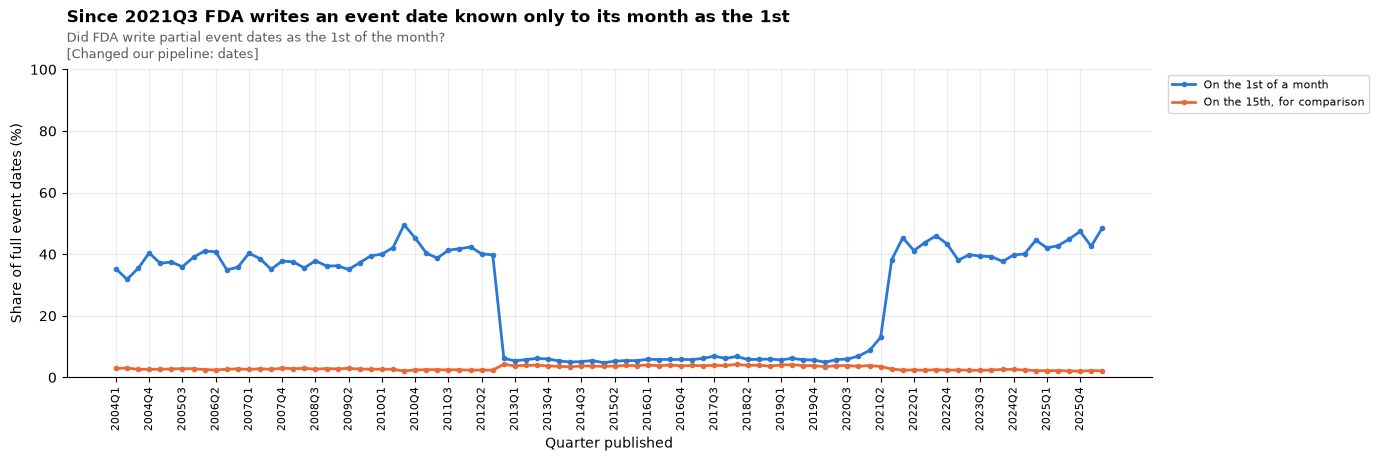

From 2021Q3 FDA writes a month-only event date as the 1st and a year-only one as 1 January, as legacy AERS did: 38% to 49% of full event dates a quarter fall on the 1st, against a median of 5.8% from 2012Q4 to 2021Q2 and 3.7% on the 15th. In those versions we read an event date on the 1st as known to its month, and on 1 January to its year, so no time to onset is counted from a day nobody reported.


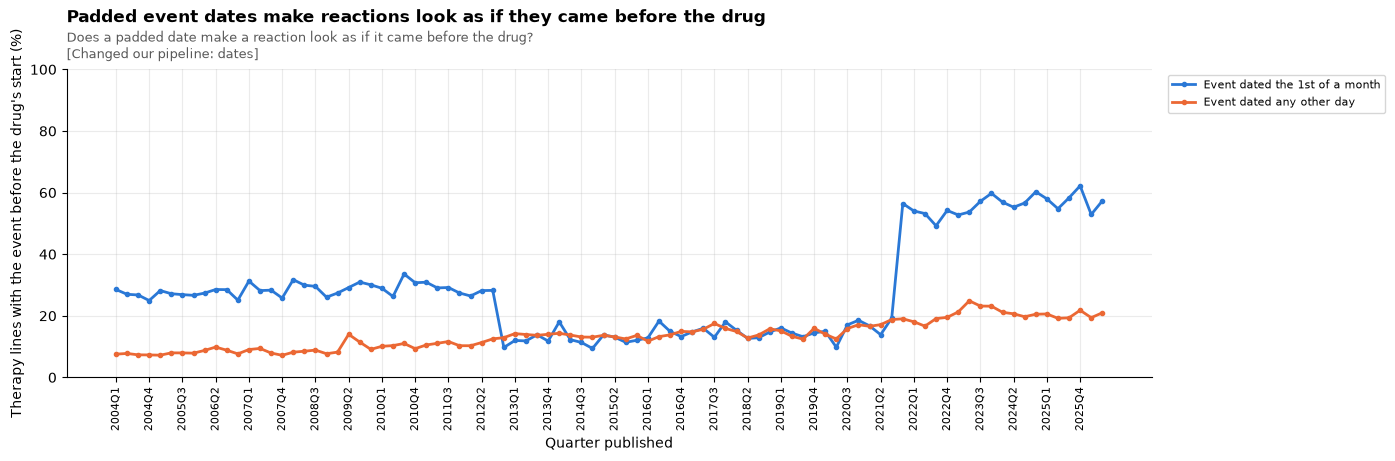

In therapy lines published from 2021Q3 a reaction dated the 1st comes before the drug's start in 56% of lines, against 20% for other days, while from 2012Q4 to 2021Q2, before the padding, the two match (14.1% and 14.3%). We count a time to onset only from an event date and a first dose both known to the day, and leave it empty when the event comes before the first dose.


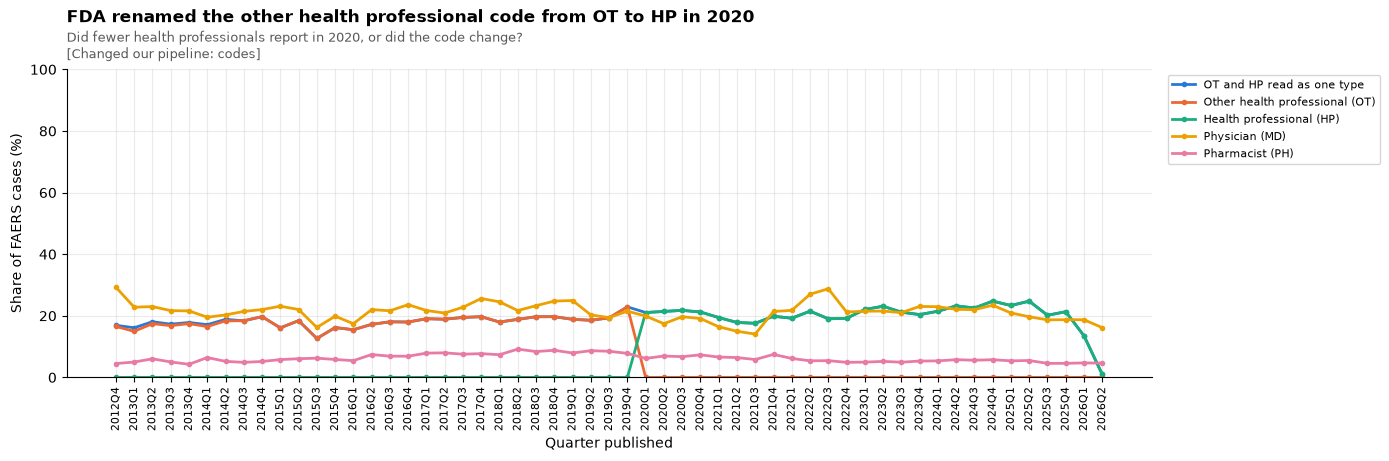

OT, other health professional, is 22.9% of FAERS cases in 2019Q4 and none after, when HP, health professional, starts at 21.1%, while physicians and pharmacists show no such step. We read both as ICH E2B(R3)'s other health professional, so a count by reporter type runs straight across 2020, with FDA's own code beside it.


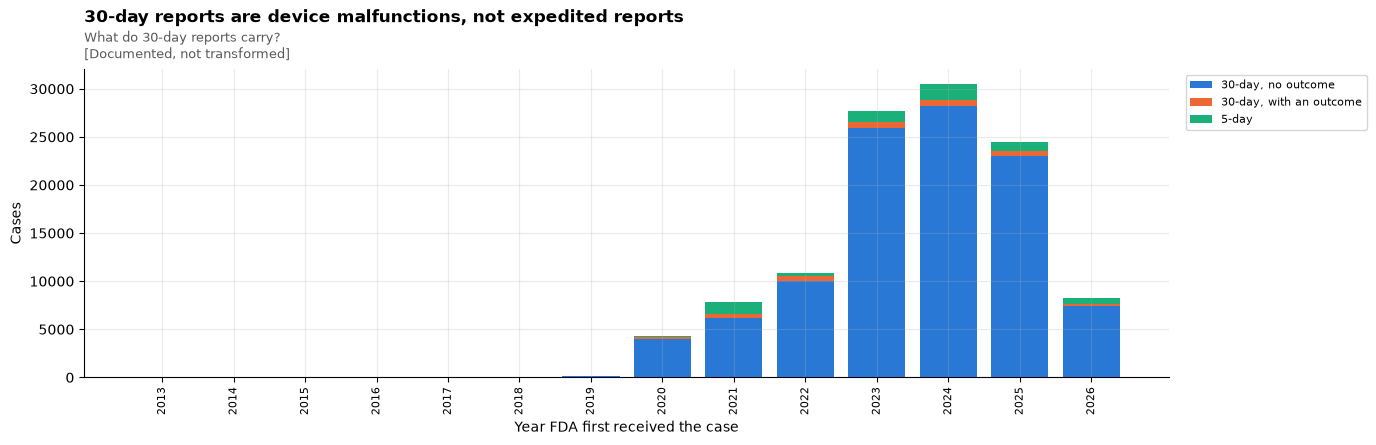

Since 2020Q1 FDA has published 107,884 cases as 30-day reports, which FDA's E2B(R3) rules keep for a malfunction of a drug-device combination product with no adverse event, and 97% give no outcome; 6,112 5-day reports ask for remedial action. We keep FDA's report type as given and count neither as an expedited 15-day report, as DiAna does.


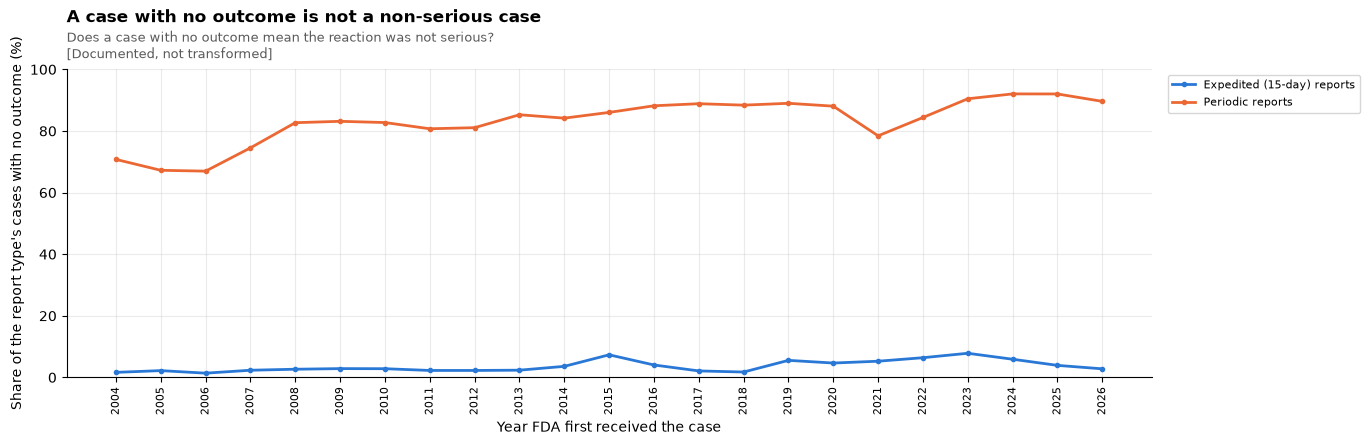

FDA gives no outcome for 435,405 cases sent as expedited reports, which go to FDA within 15 days because the reaction is serious, as well as for 86% of periodic reports, mostly about non-serious reactions. We never call a case with no outcome non-serious, as DiAna does; an expedited one says it was sent for serious reactions with no seriousness criterion.


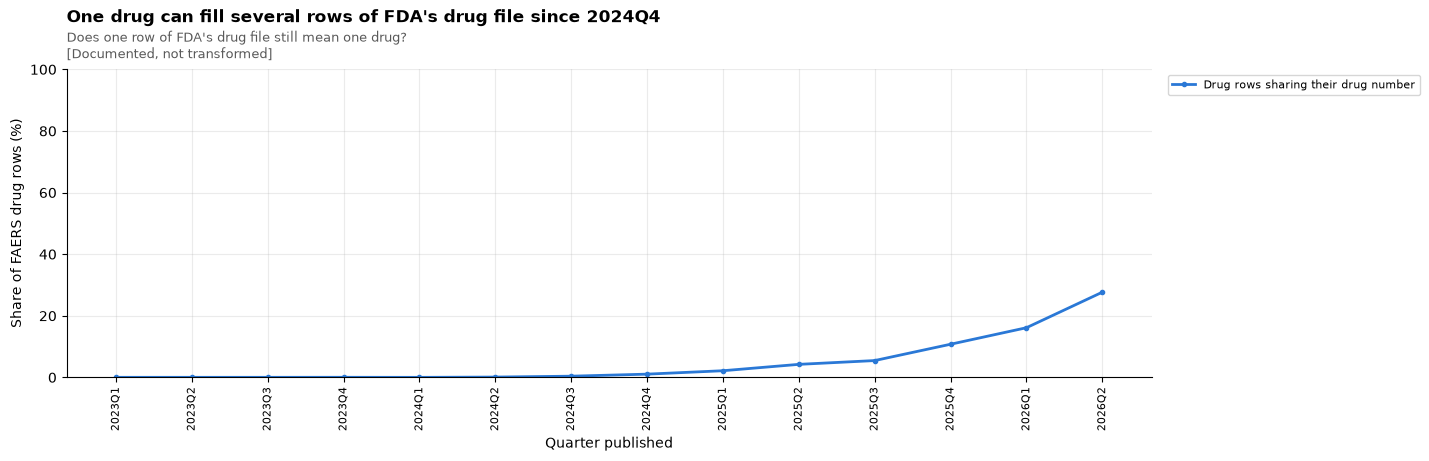

From 2024Q4 FDA often writes one drug on several rows, one per dosage regimen, under the same drug sequence number: 28% of the drug rows published in 2026Q2. A count of drugs must count each case's drug sequence numbers, not FDA's rows, and time to onset takes each drug's earliest start however many rows it has.
notebooks/out/cards/08_dates_and_codes.json


In [17]:
cards = compute_cards(
    con,
    [
        "event_dates_padded",
        "padding_puts_reactions_before_drug",
        "occupation_code_changes",
        "rept_cod_combination_products",
        "no_outcome_not_non_serious",
        "drug_seq_repeated",
    ],
)
for card in cards:
    plot_card(card)
print(write_cards(cards, "08_dates_and_codes"))

## Decisions

What each section backs, with the rule file it lives in. FDA's values stay beside every derived one.

1. **Event dates padded to the 1st** (`rules/event-date-precision.md`, section 2). In legacy AERS and in FAERS from 2021Q3, a full event date on the 1st is known to its month, on 1 January to its year; FAERS before 2021Q3 is read as written, its soft edge in 2021Q2 included. The cost is about 290,000 true 1sts that lose their day; the gain, about 1.74 million padded dates no longer read as exact days. The duplicate rules read FDA's own date, so the kept cases do not move.
2. **Dates that cannot be true** (`rules/date-limits.md`, section 1). Event, therapy start and therapy end dates only. The ceiling is the last day of the case version's quarter, a partial date compared at its own precision. The floor of a therapy date is a year before the patient's birth where the age is known, else 122 years before FDA first received the case; an event date has the 122-year floor. A date outside has no clean value; FDA's text stays. In this release: 546 event dates, 10,481 therapy starts, 3,152 therapy ends.
3. **Time to onset** (`rules/time-to-onset.md`, section 3). One value per drug record: the event date less the drug's earliest therapy start, both known to the day and inside the limits, plus one, so the first day is day 1. Empty when 0 or less, and when a start known only to its month or year could be earlier.
4. **Therapy duration** (`rules/therapy-duration.md`, section 4). From the two clean dates, else FDA's number in its unit; empty when longer than the patient's age plus a year, or than 50 years where the age is not known. No date is filled from a duration.
5. **Reporter type** (`rules/reporter-type.md`, section 5). FDA's code read as its E2B(R3) qualification through `mappings/faers/reporter_types/accepted.csv`: MD 1, PH 2, OT, HP and RN 3, LW 4, CN 5; any other code has no type.
6. **Report type and seriousness** (the rules page's "What we do not do", `src/open_altio/faers/insights/limits.yaml`, sections 6 and 8). FDA's report type is kept as given; 30DAY and 5DAY are never counted as expedited. A case with no outcome is never called non-serious, and an expedited one says it was sent for serious reactions with no criterion given. Where one most-severe outcome is needed, FDA's README order.
7. **Frequency** (the same entry, section 7). FDA's code, shown in FDA's words; never an E2B interval.
8. **Routes, and values that say nothing** (other steps). Routes are the route step's (`drug-route`). The rechallenge filler, and other values that say nothing, are the rule for values not given (`not-given`); rechallenge U is kept, since it is the commonest answer.

**Open: dose form** (section 7). DiAna's table agrees with FDA's words for 85.5% of the checked rows and says more than the words, or something else, for most of the rest. Recommendation: show FDA's text at launch, and add a reviewed dose form table after, proposed in a public issue that starts from the check in section 7.